In [3]:
import pdb
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pylab as pylab
import cartopy
import cartopy.crs as ccrs
import pickle as pkl
import glob
from metpy import calc
from metpy.units import units
import matplotlib.patches as patches
from scipy import stats
from endgame import hist2d

from matplotlib.lines import Line2D

from shared.paths import load_paths
paths = load_paths()

pylab.rcParams['figure.figsize'] = (50., 50.)
%matplotlib inline

In [2]:
cd ..

/home/users/cornkle/pythonWorkspace/proj_CEH


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# VPD helper functions
# ------------------------------------------------------------

def calc_vpd_from_t_q(t, q, p_hpa=1000.):
    """
    Calculate vapour pressure deficit from temperature and specific humidity.

    t     : temperature, usually K. If values look like Celsius, code handles it.
    q     : specific humidity, usually kg/kg. If values look like g/kg, code converts.
    p_hpa : pressure in hPa. Use 1000 hPa as near-surface approximation unless you have psfc.

    returns VPD in hPa.
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    # If q looks like g/kg, convert to kg/kg
    q = np.where(q > 0.1, q / 1000., q)

    # If T looks like Celsius, convert to Kelvin
    t_k = np.where(t < 150, t + 273.15, t)
    t_c = t_k - 273.15

    # saturation vapour pressure, hPa
    es = 6.112 * np.exp((17.67 * t_c) / (t_c + 243.5))

    # actual vapour pressure from specific humidity, hPa
    eps = 0.622
    e = (q * p_hpa) / (eps + (1 - eps) * q)

    vpd = es - e
    return vpd


def add_vpd_to_abs_and_anom(abs_df, anom_df, suffix='1deg', p_hpa=1000.):
    """
    Adds VPD to both:
    - abs_df: storm-day absolute VPD
    - anom_df: storm-day VPD anomaly relative to that period's own climate

    Uses:
    storm climate T = storm absolute T - storm T anomaly
    storm climate q = storm absolute q - storm q anomaly
    """

    tvar = f't_srfc_{suffix}'
    qvar = f'q_srfc_{suffix}'
    outvar = f'vpd_srfc_{suffix}'

    # storm-day absolute VPD
    vpd_abs = calc_vpd_from_t_q(abs_df[tvar], abs_df[qvar], p_hpa=p_hpa)

    # reconstruct that period's local/day climatology for T and q
    t_clim = abs_df[tvar] - anom_df[tvar]
    q_clim = abs_df[qvar] - anom_df[qvar]

    # climatological VPD
    vpd_clim = calc_vpd_from_t_q(t_clim, q_clim, p_hpa=p_hpa)

    # add to dataframes
    abs_df[outvar] = vpd_abs
    anom_df[outvar] = vpd_abs - vpd_clim

    return abs_df, anom_df

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def calc_ef(lh, sh):
    """
    Evaporative fraction:
        EF = LH / (LH + SH)

    Assumes LH and SH are in the same units, e.g. W m-2.
    """
    lh = np.asarray(lh, dtype=float)
    sh = np.asarray(sh, dtype=float)

    denom = lh + sh
    ef = np.where(np.isclose(denom, 0) | np.isnan(denom), np.nan, lh / denom)
    return ef


def add_ef_to_abs_and_anom(abs_df, anom_df, suffix='1deg'):
    """
    Adds:
    - ef_1deg to abs_df  = EF from storm-day absolute LH/SH
    - ef_1deg to anom_df = EF_abs - EF_clim

    Do this separately for hist and fut.
    """

    lhvar = f'lh_{suffix}'
    shvar = f'sh_{suffix}'
    outvar = f'ef_{suffix}'

    # storm-day absolute EF
    ef_abs = calc_ef(abs_df[lhvar], abs_df[shvar])

    # reconstruct each period's climatological LH/SH
    lh_clim = abs_df[lhvar] - anom_df[lhvar]
    sh_clim = abs_df[shvar] - anom_df[shvar]

    # climatological EF
    ef_clim = calc_ef(lh_clim, sh_clim)

    # add derived absolute and derived anomaly
    abs_df[outvar] = ef_abs*100
    anom_df[outvar] = (ef_abs - ef_clim)*100

    return abs_df, anom_df

In [6]:
import numpy as np

def calc_thetae_from_t_q(t, q, p_hpa=925.):
    """
    Calculate equivalent potential temperature from temperature and specific humidity.

    t     : temperature, K or degC
    q     : specific humidity, kg/kg or g/kg
    p_hpa : pressure in hPa

    returns theta-e in K
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    # q: g/kg -> kg/kg if needed
    q = np.where(q > 0.1, q / 1000., q)

    # T: Celsius -> Kelvin if needed
    t_k = np.where(t < 150, t + 273.15, t)

    # avoid impossible q values
    q = np.where((q <= 0) | (q >= 1), np.nan, q)

    # mixing ratio, kg/kg
    r = q / (1. - q)

    # vapour pressure, hPa
    eps = 0.622
    e = (q * p_hpa) / (eps + (1. - eps) * q)
    e = np.where(e <= 0, np.nan, e)

    # dewpoint from vapour pressure, K
    ln_ratio = np.log(e / 6.112)
    td_c = (243.5 * ln_ratio) / (17.67 - ln_ratio)
    td_k = td_c + 273.15

    # LCL temperature, K; Bolton-style approximation
    tlcl = 1. / (1. / (td_k - 56.) + np.log(t_k / td_k) / 800.) + 56.

    # potential temperature
    rd_cp = 0.2854
    theta = t_k * (1000. / p_hpa) ** rd_cp

    # equivalent potential temperature
    thetae = theta * np.exp((3376. / tlcl - 2.54) * r * (1. + 0.81 * r))

    return thetae

In [7]:
def add_thetae_to_abs_and_anom(abs_df, anom_df, suffix='1deg', p_hpa=925.):
    """
    Adds theta-e to storm-day absolute and anomaly dataframes.

    abs_df  : lhist or lfut
    anom_df : lahist or lafut

    Adds:
        thetae_calc_1deg to abs_df
        thetae_calc_1deg to anom_df

    thetae anomaly is calculated as:
        thetae_abs - thetae_clim
    """

    tvar = f't_srfc_{suffix}'
    qvar = f'q_srfc_{suffix}'
    outvar = f'thetae_{suffix}'

    thetae_abs = calc_thetae_from_t_q(abs_df[tvar], abs_df[qvar], p_hpa=p_hpa)

    t_clim = abs_df[tvar] - anom_df[tvar]
    q_clim = abs_df[qvar] - anom_df[qvar]

    thetae_clim = calc_thetae_from_t_q(t_clim, q_clim, p_hpa=p_hpa)

    abs_df[outvar] = thetae_abs
    anom_df[outvar] = thetae_abs - thetae_clim

    return abs_df, anom_df

In [8]:
import numpy as np

def saturation_vapour_pressure_hpa(t_k):
    """
    Saturation vapour pressure over liquid water, hPa.
    Input T in K.
    """
    t_c = t_k - 273.15
    return 6.112 * np.exp((17.67 * t_c) / (t_c + 243.5))


def calc_thetae_from_t_q(t, q, p_hpa=925.):
    """
    Equivalent potential temperature from T and specific humidity.

    t     : K or degC
    q     : kg/kg or g/kg
    p_hpa : hPa

    returns theta-e in K
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    q = np.where(q > 0.1, q / 1000., q)       # g/kg -> kg/kg if needed
    t_k = np.where(t < 150, t + 273.15, t)   # degC -> K if needed

    q = np.where((q <= 0) | (q >= 1), np.nan, q)

    r = q / (1. - q)

    eps = 0.622
    e = (q * p_hpa) / (eps + (1. - eps) * q)
    e = np.where(e <= 0, np.nan, e)

    ln_ratio = np.log(e / 6.112)
    td_c = (243.5 * ln_ratio) / (17.67 - ln_ratio)
    td_k = td_c + 273.15

    tlcl = 1. / (1. / (td_k - 56.) + np.log(t_k / td_k) / 800.) + 56.

    theta = t_k * (1000. / p_hpa) ** 0.2854
    thetae = theta * np.exp((3376. / tlcl - 2.54) * r * (1. + 0.81 * r))

    return thetae


def calc_thetaes_from_t(t, p_hpa=650.):
    """
    Saturated equivalent potential temperature from T and pressure.

    t     : K or degC
    p_hpa : hPa

    returns saturated theta-e in K
    """

    t = np.asarray(t, dtype=float)
    t_k = np.where(t < 150, t + 273.15, t)

    eps = 0.622

    es = saturation_vapour_pressure_hpa(t_k)
    es = np.where(es >= 0.99 * p_hpa, np.nan, es)

    rs = eps * es / (p_hpa - es)

    # saturated parcel: dewpoint = temperature, LCL approximately T
    tlcl = t_k

    theta = t_k * (1000. / p_hpa) ** 0.2854
    thetaes = theta * np.exp((3376. / tlcl - 2.54) * rs * (1. + 0.81 * rs))

    return thetaes

In [9]:
def add_cape_proxy_to_abs_and_anom(abs_df, anom_df, suffix='1deg',
                                   p_srfc_hpa=925., p_mid_hpa=650.):
    """
    Adds table-based two-level CAPE proxy:

        cape_proxy_calc = thetae_srfc - thetaes_mid

    to both absolute and anomaly dataframes.

    The anomaly is calculated as:

        cape_proxy_abs - cape_proxy_clim

    not from anomaly T/q directly.
    """

    t_s_var = f't_srfc_{suffix}'
    q_s_var = f'q_srfc_{suffix}'
    t_m_var = f't_mid_{suffix}'

    thetae_var  = f'thetae_calc_{suffix}'
    thetaes_var = f'thetaes_mid_calc_{suffix}'
    cape_var    = f'cape_proxy_calc_{suffix}'

    # storm-day absolute values
    thetae_s_abs = calc_thetae_from_t_q(abs_df[t_s_var], abs_df[q_s_var],
                                        p_hpa=p_srfc_hpa)

    thetaes_m_abs = calc_thetaes_from_t(abs_df[t_m_var],
                                        p_hpa=p_mid_hpa)

    cape_abs = thetae_s_abs - thetaes_m_abs

    # reconstruct period climatology
    t_s_clim = abs_df[t_s_var] - anom_df[t_s_var]
    q_s_clim = abs_df[q_s_var] - anom_df[q_s_var]
    t_m_clim = abs_df[t_m_var] - anom_df[t_m_var]

    thetae_s_clim = calc_thetae_from_t_q(t_s_clim, q_s_clim,
                                         p_hpa=p_srfc_hpa)

    thetaes_m_clim = calc_thetaes_from_t(t_m_clim,
                                         p_hpa=p_mid_hpa)

    cape_clim = thetae_s_clim - thetaes_m_clim

    # add to dataframes
    abs_df[thetae_var] = thetae_s_abs
    abs_df[thetaes_var] = thetaes_m_abs
    abs_df[cape_var] = cape_abs

    anom_df[thetae_var] = thetae_s_abs - thetae_s_clim
    anom_df[thetaes_var] = thetaes_m_abs - thetaes_m_clim
    anom_df[cape_var] = cape_abs - cape_clim

    return abs_df, anom_df

In [10]:
lhist_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/hist_mean_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE_SBCAPE.csv', index_col=0, low_memory=False).T
lfut_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/fut_mean_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE_SBCAPE.csv', index_col=0, low_memory=False).T

In [11]:
lahist_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/hist_anom_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE.csv', index_col=0, low_memory=False).T
lafut_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/fut_anom_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE.csv', index_col=0, low_memory=False).T

In [12]:
for dat in [lahist_orig, lafut_orig, lhist_orig, lfut_orig]:
    for var in dat.keys():
        try:
            dat[var] = dat[var].astype(float)
        except:
            pass

In [13]:
keys = ["pmax", "area", "area_1mm"]
 
common = pd.merge(lahist_orig[keys].drop_duplicates(),lhist_orig[keys].drop_duplicates(),on=keys,how="inner")
lahist_orig = lahist_orig.merge(common, on=keys, how="inner")
lhist_orig = lhist_orig.merge(common, on=keys, how="inner")
 
common = pd.merge(lafut_orig[keys].drop_duplicates(),lfut_orig[keys].drop_duplicates(),on=keys,how="inner")
lafut_orig = lafut_orig.merge(common, on=keys, how="inner")
lfut_orig = lfut_orig.merge(common, on=keys, how="inner")

In [14]:
lahist, lafut, lhist, lfut= [df.copy() for df in (lahist_orig, lafut_orig, lhist_orig, lfut_orig)]

20014

In [16]:
len(lafut)

14506

In [17]:
np.unique(lahist['month'])

array([7., 8., 9.])

In [18]:
np.unique(lhist['hour'])

array([17., 18., 19.])

In [19]:
dtag = '2deg'

lhist, lahist = add_vpd_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_vpd_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_ef_to_abs_and_anom(lhist, lahist, suffix=dtag)
lfut,  lafut  = add_ef_to_abs_and_anom(lfut,  lafut,  suffix=dtag)

lhist, lahist = add_thetae_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_thetae_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_cape_proxy_to_abs_and_anom(lhist, lahist, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)
lfut, lafut = add_cape_proxy_to_abs_and_anom(lfut, lafut, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)

In [38]:
dtag = '1deg'

lhist, lahist = add_vpd_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_vpd_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_ef_to_abs_and_anom(lhist, lahist, suffix=dtag)
lfut,  lafut  = add_ef_to_abs_and_anom(lfut,  lafut,  suffix=dtag)

lhist, lahist = add_thetae_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_thetae_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_cape_proxy_to_abs_and_anom(lhist, lahist, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)
lfut, lafut = add_cape_proxy_to_abs_and_anom(lfut, lafut, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)

In [39]:
print(list(lfut.keys()))

['tcwv_0.25deg', 'tcwv_1deg', 'tcwv_2deg', 'tcwv_fullBox', 'sh_0.25deg', 'sh_1deg', 'sh_2deg', 'sh_fullBox', 'lh_0.25deg', 'lh_1deg', 'lh_2deg', 'lh_fullBox', 't2_0.25deg', 't2_1deg', 't2_2deg', 't2_fullBox', 'q2_0.25deg', 'q2_1deg', 'q2_2deg', 'q2_fullBox', 'shear_0.25deg', 'shear_1deg', 'shear_2deg', 'shear_fullBox', 'u_mid_0.25deg', 'u_mid_1deg', 'u_mid_2deg', 'u_mid_fullBox', 'u_srfc_0.25deg', 'u_srfc_1deg', 'u_srfc_2deg', 'u_srfc_fullBox', 'v_mid_0.25deg', 'v_mid_1deg', 'v_mid_2deg', 'v_mid_fullBox', 'v_srfc_0.25deg', 'v_srfc_1deg', 'v_srfc_2deg', 'v_srfc_fullBox', 'q_mid_0.25deg', 'q_mid_1deg', 'q_mid_2deg', 'q_mid_fullBox', 't_mid_0.25deg', 't_mid_1deg', 't_mid_2deg', 't_mid_fullBox', 't_srfc_0.25deg', 't_srfc_1deg', 't_srfc_2deg', 't_srfc_fullBox', 'q_srfc_0.25deg', 'q_srfc_1deg', 'q_srfc_2deg', 'q_srfc_fullBox', 'geoH_srfc_0.25deg', 'geoH_srfc_1deg', 'geoH_srfc_2deg', 'geoH_srfc_fullBox', 'lsRain_noon_0.25deg', 'lsRain_noon_1deg', 'lsRain_noon_2deg', 'lsRain_noon_fullBox', 'lw

In [40]:
print(len(lhist))
print(len(lfut))

19894
14455


In [41]:
pmax_thresh = 1
area_thresh = 500000

lahist = lahist[(lhist['pmax']>=1) &  (lhist['area']*4.4**2<area_thresh)]
lhist = lhist[(lhist['pmax']>=1)  &  (lhist['area']*4.4**2<area_thresh) ]

lafut = lafut[(lfut['pmax']>=1)  &  (lfut['area']*4.4**2<area_thresh)]
lfut = lfut[(lfut['pmax']>=1)  &  (lfut['area']*4.4**2<area_thresh) ]

In [42]:
print(len(lhist))
print(len(lfut))

19894
14455


<>:225: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
<>:225: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
/tmp/ipykernel_325/976071489.py:225: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
  plot_group_pdf(axs[5], r'thetae_'+dtag,   '$\Theta$-e','K',         zero_line=False, nbins=34, qrange=(1, 99))


50 -50
-3.069373148619687 1.2701124875938048 -4.469566451840368 0.1544570948576085
4748 4877 3322 3515
ef_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 71.70716709741228 51.78664488877122 67.39305112546415 40.216112504845896
ICAPEfull_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 1.5137806427615885 1.7465564737689778 2.4842389614011724 2.766528993649695
div_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 0.24387918277568804 -0.02511288282723655 -0.11917826459745294 -0.6231096971160291
t2_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 301.4548731754117 303.7122586309175 306.9875195323087 309.65947821928194
thetae_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 351.3282583724189 351.8031484535933 374.47563088753714 374.0292757318765
geoH_srfc_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 782.1913220788196 779.1470443832536 797.481498154936 791.6238882104698
shear_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -15.931548503376987 -17.126162794466655 -16.5479184607855

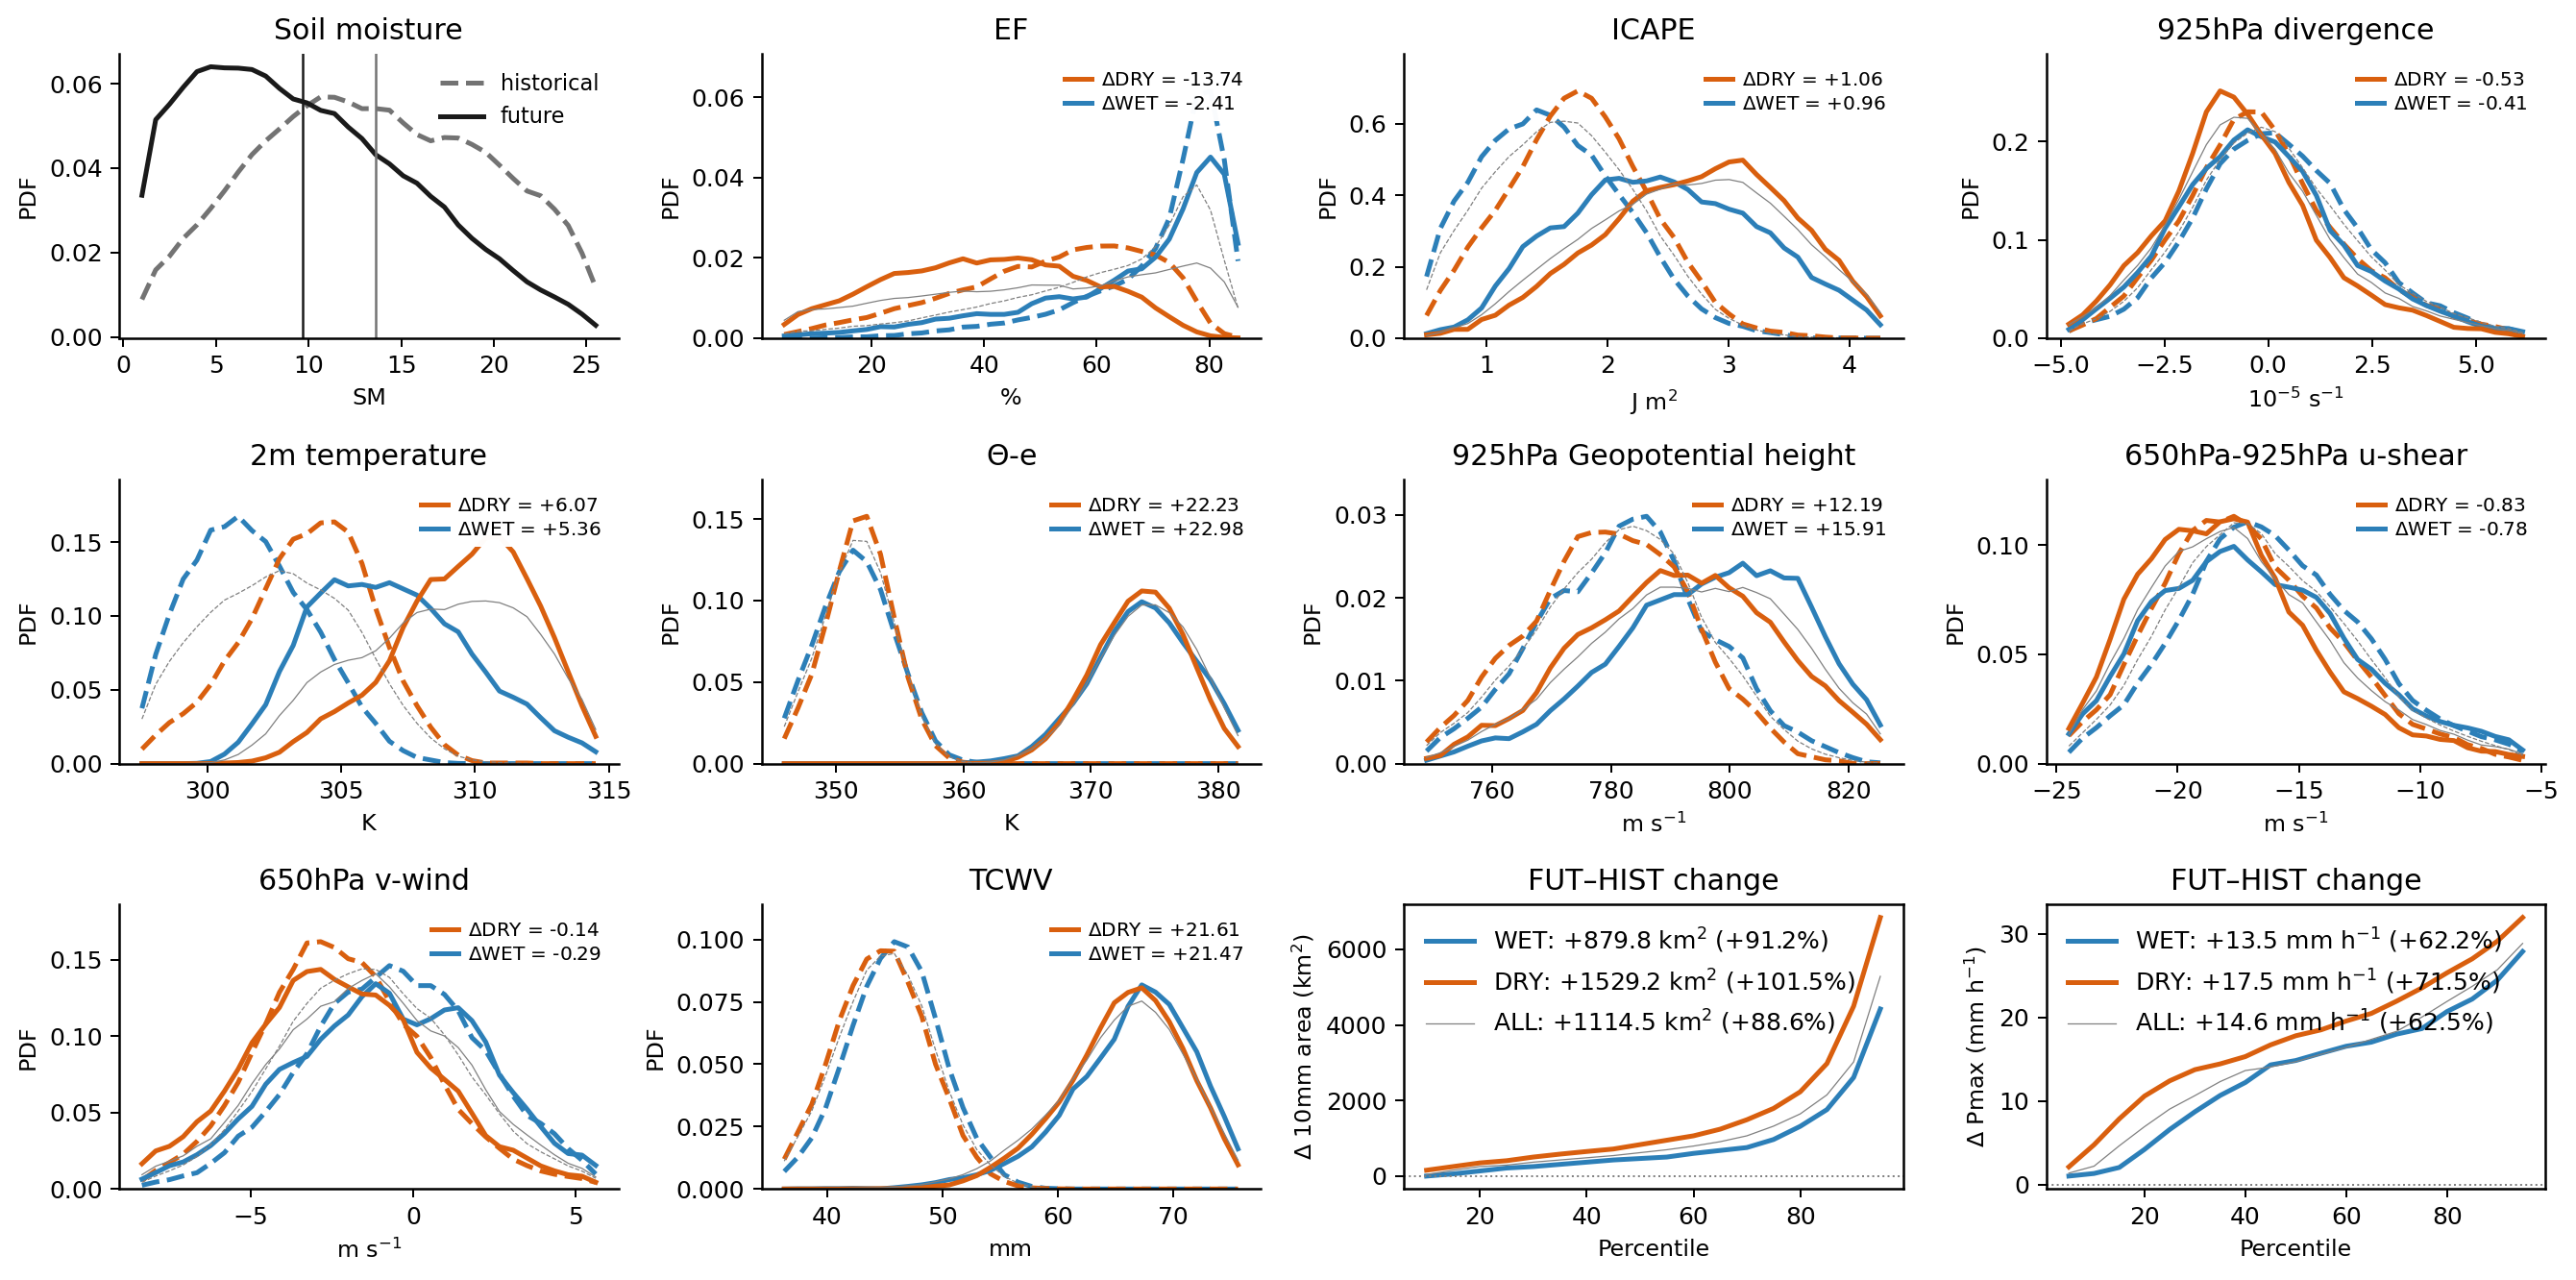

-0.5 -2
-3.069373148619687 1.2701124875938048 -4.469566451840368 0.1544570948576085
1102 1192 668 741
ef_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 72.33977592899174 50.60224726705177 69.36214426435 40.18916279230073
ICAPEfull_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 1.5136644313013368 1.695189084154328 2.5482763799313903 2.8035511948820284
div_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 0.17058074137705745 0.07918345931043032 -0.03655507634937859 -0.5727024541676041
t2_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 301.3395456133517 303.8987734690442 306.8173944446067 309.7908921604597
thetae_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 351.5842880299076 351.6240502718363 374.9797069115307 374.29406435810427
geoH_srfc_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 780.3243860187816 779.2020335838363 795.8037938902594 791.6326337210074
shear_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -16.300394294375465 -16.770842856553628 -17.014158330976773 -18

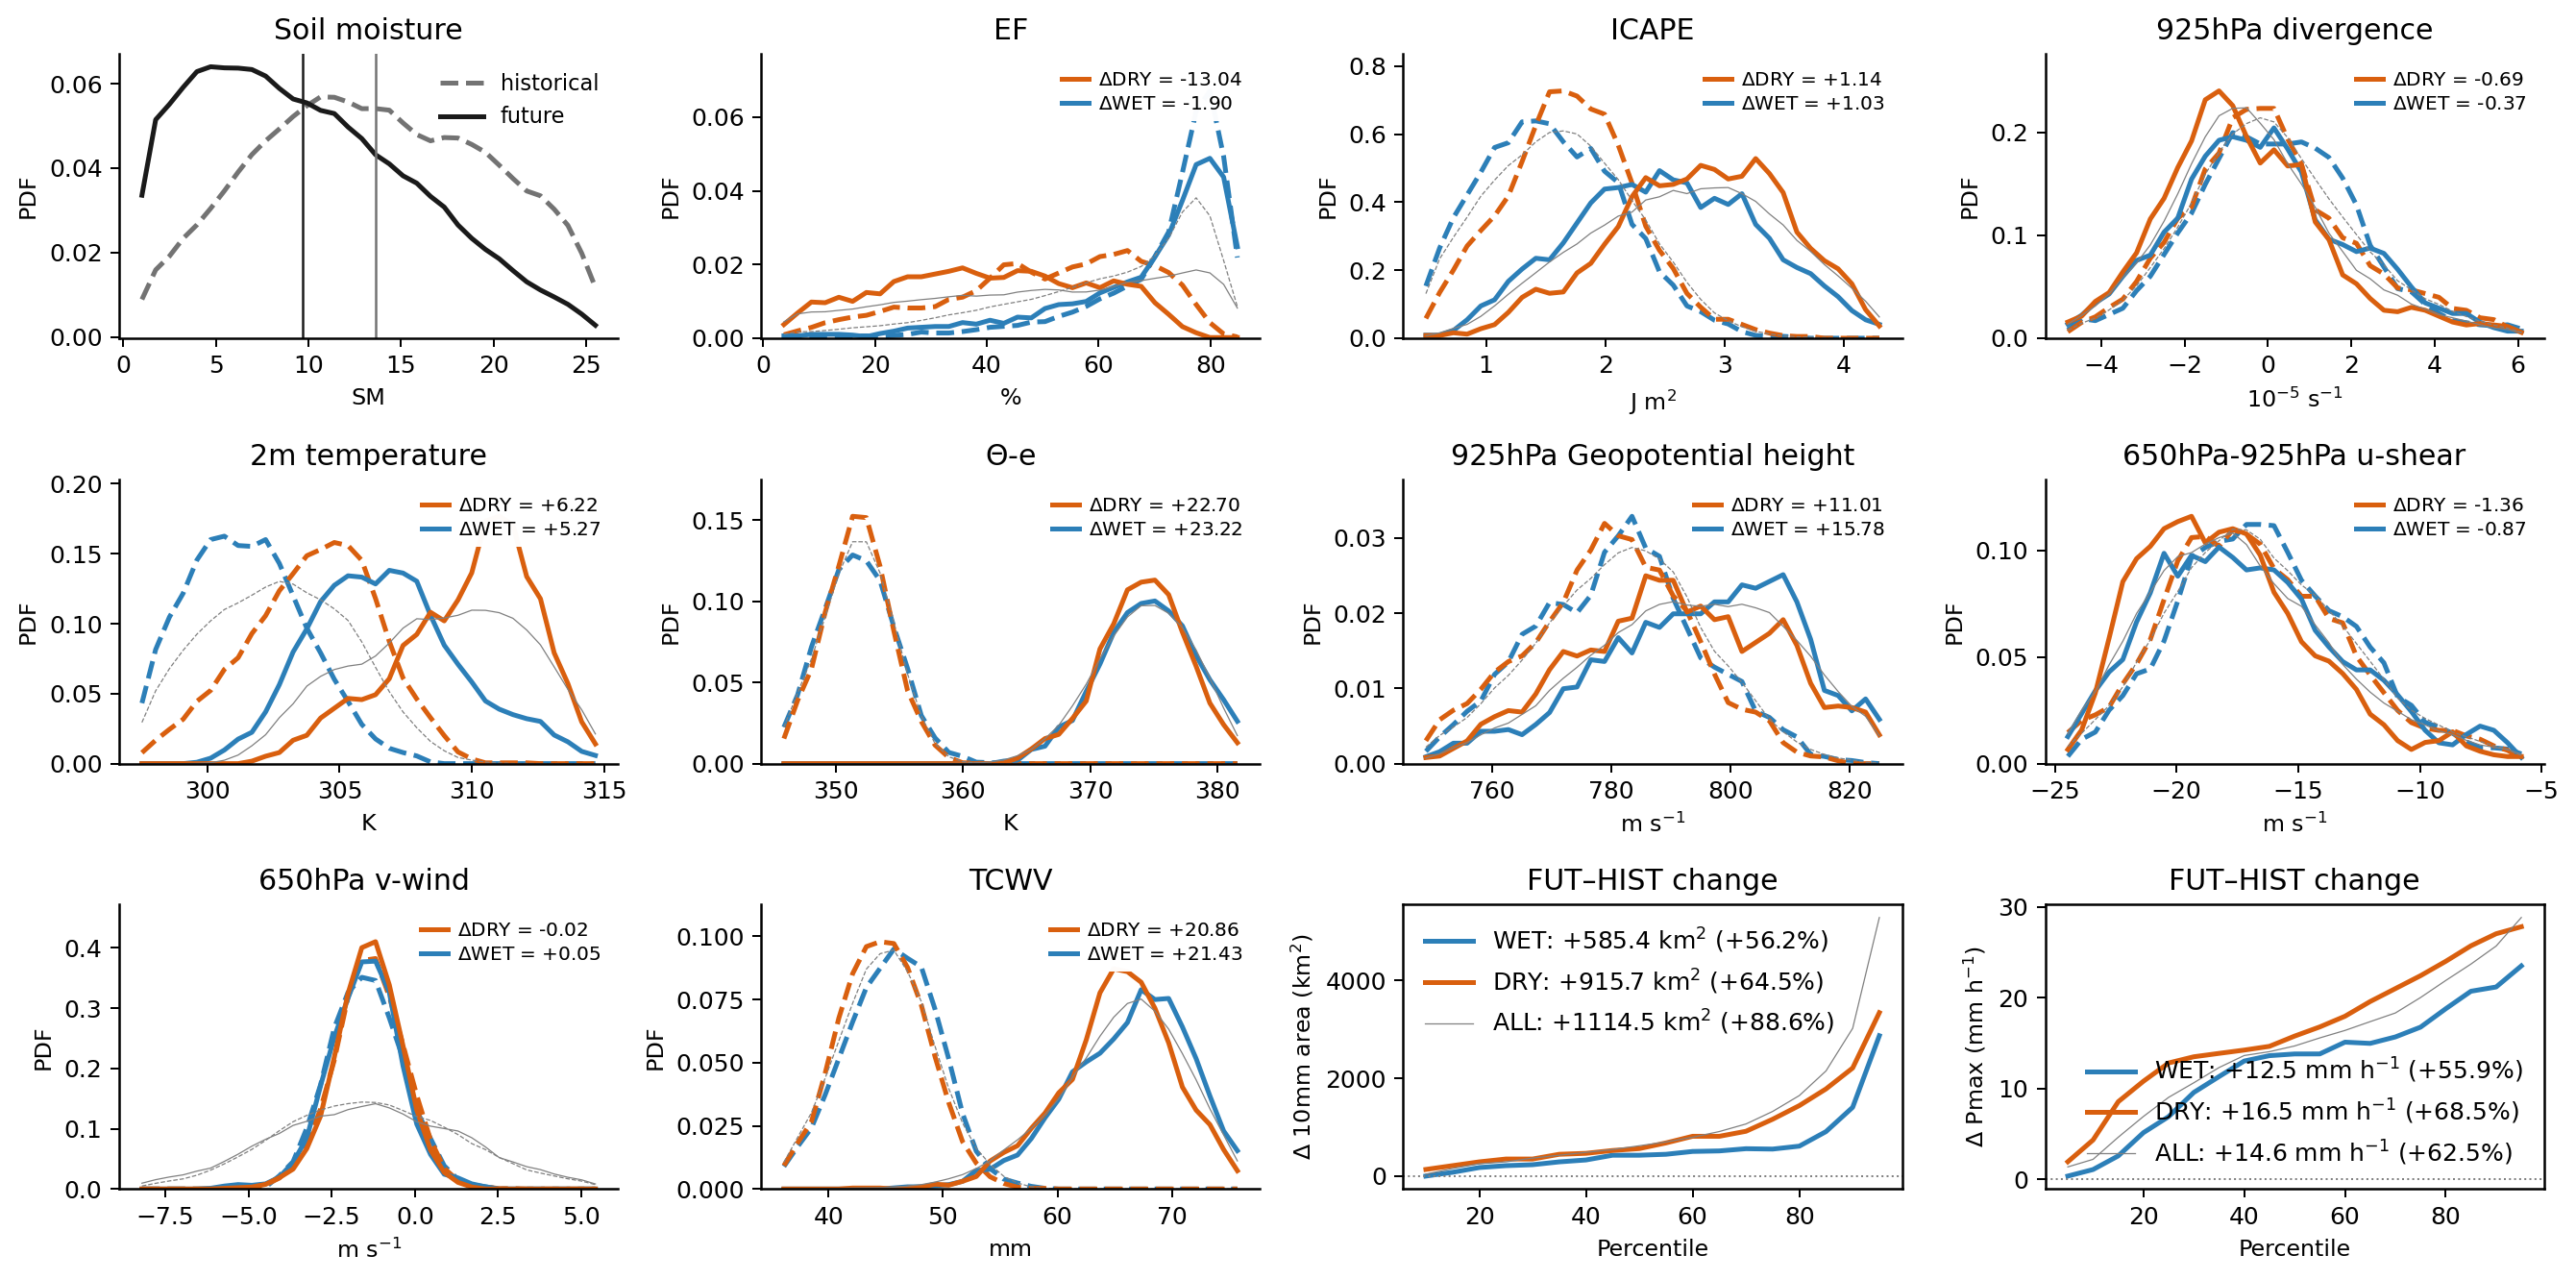

In [43]:
dtag = '1deg'

output_file1 = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/cp4_paper_ABSOLUTE_PDFs_Sfig3_'+dtag+'.png'
output_file2 = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/cp4_paper_ABSOLUTE_PDFs-vmid_Sfig4_'+dtag+'.png'

def plot_this(v_thresh_up=50, v_thresh_down=-50, output_file=output_file1):
    # ------------------------------------------------------------
    # SM split (same logic as your current code)
    # ------------------------------------------------------------

    print(v_thresh_up, v_thresh_down)
    
    hist_north = (lhist['v_mid_fullBox'] < v_thresh_up) & (lhist['v_mid_fullBox'] > v_thresh_down)
    fut_north  = (lfut['v_mid_fullBox'] < v_thresh_up) & (lfut['v_mid_fullBox'] > v_thresh_down)
    
    histp25, histp75 = np.nanpercentile(lahist['SM_2deg'], [25, 75])
    futp25, futp75   = np.nanpercentile(lafut['SM_2deg'], [25, 75])
    
    histposlow  = (lahist['SM_2deg'] > histp75) & hist_north   # WET
    histposhigh = (lahist['SM_2deg'] < histp25) & hist_north   # DRY
    histall = lhist['pmax']>=1
    
    futposlow   = (lafut['SM_2deg'] > futp75) & fut_north    # WET
    futposhigh  = (lafut['SM_2deg'] < futp25) & fut_north    # DRY
    futall =  lfut['pmax']>=1

    
    print(histp25, histp75, futp25, futp75)
    print(np.sum(histposlow), np.sum(histposhigh), np.sum(futposlow), np.sum(futposhigh))
    
    
    # ------------------------------------------------------------
    # Colours / styles
    # ------------------------------------------------------------
    wet_col  = '#2C7FB8'
    dry_col  = '#D95F0E'
    hist_col = '0.45'
    fut_col  = '0.10'
    
    
    # ------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------
    def _clean(x, scale=1):
        x = np.asarray(x, dtype=float) * scale
        return x[np.isfinite(x)]
    
    def _smooth(y, n=3):
        if n <= 1:
            return y
        kernel = np.ones(n) / n
        return np.convolve(y, kernel, mode='same')
    
    def _make_bins(arrs, nbins=36, qrange=(1, 99)):
        zz = np.concatenate([a for a in arrs if len(a) > 0])
        lo, hi = np.nanpercentile(zz, qrange)
        return np.linspace(lo, hi, nbins + 1)
    
    def _pdf(vals, bins, smooth=3):
        h, edges = np.histogram(vals, bins=bins, density=True)
        mids = 0.5 * (edges[1:] + edges[:-1])
        return mids, _smooth(h, n=smooth)
    
    def style_ax(ax):
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(direction='out')
    
    def plot_sm_pdf(ax):
        hsm = _clean(lhist['SM_2deg'])
        fsm = _clean(lfut['SM_2deg'])
        bins = _make_bins([hsm, fsm], nbins=34, qrange=(1, 99))
    
        x, y = _pdf(hsm, bins, smooth=3)
        ax.plot(x, y, color=hist_col, ls='--', lw=2, label='historical')
    
        x, y = _pdf(fsm, bins, smooth=3)
        ax.plot(x, y, color=fut_col, ls='-', lw=2, label='future')
    
        # ax.axvline(histp25, color=hist_col, ls='--', lw=1)
        # ax.axvline(histp75, color=hist_col, ls='--', lw=1)
        # ax.axvline(futp25,  color=fut_col,  ls='-',  lw=1)
        # ax.axvline(futp75,  color=fut_col,  ls='-',  lw=1)
        ax.axvline(np.mean(lhist['SM_2deg']),  color=hist_col,  ls='-',  lw=1)
        ax.axvline(np.mean(lfut['SM_2deg']),  color=fut_col,  ls='-',  lw=1)
    
        ymax = ax.get_ylim()[1]
        # ax.text(histp25, ymax*0.95, 'H25', rotation=90, va='top', ha='right', fontsize=8, color=hist_col)
        # ax.text(histp75, ymax*0.95, 'H75', rotation=90, va='top', ha='right', fontsize=8, color=hist_col)
        # ax.text(futp25,  ymax*0.85, 'F25', rotation=90, va='top', ha='left',  fontsize=8, color=fut_col)
        # ax.text(futp75,  ymax*0.85, 'F75', rotation=90, va='top', ha='left',  fontsize=8, color=fut_col)
    
        ax.set_title('Soil moisture')
        ax.set_xlabel('SM')
        ax.set_ylabel('PDF')
        ax.legend(frameon=False, fontsize=9)
        style_ax(ax)
    
    
    def plot_group_pdf(ax, var, title, xlabel, scale=1, zero_line=False,
                       nbins=34, qrange=(1, 99), smooth=3, delta_decimals=2):
    
        # Absolute values for TCW, v-wind and ICAPE; anomalies otherwise
        absolute_vars = [] #'tcwv_'+dtag,  'ICAPEfull_'+dtag, 'shear_'+dtag, 'v_mid_'+dtag
        hdata, fdata = (lhist, lfut) if var in absolute_vars else (lhist, lfut)
    
        hwet = _clean(hdata.loc[histposlow, var], scale)
        hdry = _clean(hdata.loc[histposhigh, var], scale)
        fwet = _clean(fdata.loc[futposlow, var], scale)
        fdry = _clean(fdata.loc[futposhigh, var], scale)
        hall = _clean(hdata.loc[histall, var], scale)
        fall = _clean(fdata.loc[futall, var], scale)
    
        # Diagnostic: absolute environmental means, as in your original code
        absolute_means = [
            np.mean(_clean(data.loc[mask, var], scale))
            for data, mask in [(lhist, histposlow), (lhist, histposhigh),
                               (lfut, futposlow), (lfut, futposhigh)]
        ]
        print(var, 'absolute means (H-WET, H-DRY, F-WET, F-DRY):',
              *absolute_means)
    
        bins = _make_bins([hwet, hdry, fwet, fdry, hall, fall],
                          nbins, qrange)
    
        curves = [
            (hwet, wet_col, '--', 'hist-WET', 2),
            (hdry, dry_col, '--', 'hist-DRY', 2),
            (fwet, wet_col, '-', 'fut-WET', 2),
            (fdry, dry_col, '-', 'fut-DRY', 2),
            (hall, 'grey', '--', 'hist-ALL', 0.5),
            (fall, 'grey', '-', 'fut-ALL', 0.5)
        ]

        ymax = 0
    
        for vals, col, ls, lab, lw in curves:
            x, y = _pdf(vals, bins, smooth=smooth)
            ax.plot(x, y, color=col, ls=ls, lw=lw, label=lab)

            ymax = max(ymax, np.nanmax(y))

        ax.set_ylim(0, ymax * 1.15)
    
        # FUT minus HIST difference between group medians
        delta_dry = np.nanmedian(fdry) - np.nanmedian(hdry)
        delta_wet = np.nanmedian(fwet) - np.nanmedian(hwet)
    
        delta_handles = [
            Line2D([], [], color=dry_col, lw=2,
                   label=fr'$\Delta$DRY = {delta_dry:+.{delta_decimals}f}'),
            Line2D([], [], color=wet_col, lw=2,
                   label=fr'$\Delta$WET = {delta_wet:+.{delta_decimals}f}')
        ]
    
        delta_legend = ax.legend(
            handles=delta_handles,
            loc='upper right',
            frameon=True,
            framealpha=0.85,
            facecolor='white',
            edgecolor='none',
            fontsize=8,
            handlelength=1.4,
            handletextpad=0.5,
            borderpad=0.4,
            labelspacing=0.3
        )
    
        # Preserve this legend if another legend is subsequently added
        ax.add_artist(delta_legend)
    
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('PDF')
        style_ax(ax)
    
    
    def _plot_change_panel(ax, var, pp, factor, unit, ylabel):
            groups = [('WET', histposlow, futposlow, '#2C7FB8', 2),
                      ('DRY', histposhigh, futposhigh, '#D95F0E', 2),
                      ('ALL', histall, futall, 'grey', 0.5)]
            
            for label, hmask, fmask, color, lw in groups:
                hist = np.nanpercentile(lahist.loc[hmask, var] * factor, pp)
                fut = np.nanpercentile(lafut.loc[fmask, var] * factor, pp)
                change = fut - hist
                absolute = np.mean(change)
                baseline = np.mean(hist)
                relative = 100 * absolute / baseline if baseline != 0 else np.nan
            
                legend = f'{label}: {absolute:+.1f} {unit} ({relative:+.1f}%)'
                ax.plot(pp, change, color=color, lw=lw, label=legend)
            
            ax.axhline(0, color='0.5', ls=':', lw=0.8)
            ax.set_xlabel('Percentile')
            ax.set_ylabel(ylabel)
            ax.set_title('FUT–HIST change')
            ax.legend(frameon=False)
    
    
    def plot_area_panel(ax):
            _plot_change_panel(ax, 'area_10mm', np.arange(10, 100, 5), 4.4**2,
                               r'km$^2$', r'$\Delta$ 10mm area (km$^2$)')
    
    
    def plot_pmax_panel(ax):
            _plot_change_panel(ax, 'pmax', np.arange(5, 100, 5), 1,
                               r'mm h$^{-1}$', r'$\Delta$ Pmax (mm h$^{-1}$)')
    
    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    fig, axs = plt.subplots(3,4, figsize=(15, 7.5), dpi=180)
    axs = axs.ravel()
    
    # 1) full SM distribution
    plot_sm_pdf(axs[0])
    
    # 2-6) associated environmental variables
    plot_group_pdf(axs[1], 'ef_'+dtag,   'EF',         '%', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[2], r'ICAPEfull_'+dtag,   'ICAPE',       r'J m$^{2}$', scale=1e-6, zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[3], 'div_'+dtag,  '925hPa divergence',     r'$10^{-5}$ s$^{-1}$', scale=1e5, zero_line=True, nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[4], 't2_'+dtag,   r'2m temperature' ,       'K', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[5], r'thetae_'+dtag,   '$\Theta$-e','K',         zero_line=False, nbins=34, qrange=(1, 99))
    
                   
    
    # 7-8) storm characteristics
    plot_group_pdf(axs[6], r'geoH_srfc_'+dtag, r'925hPa Geopotential height', r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[7], r'shear_'+dtag, r'650hPa-925hPa u-shear', r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[8], r'v_mid_'+dtag, r'650hPa v-wind ',       r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[9], 'tcwv_'+dtag,'TCWV','mm',         zero_line=False, nbins=34, qrange=(1, 99))
    
                   
    
    # 7-8) storm characteristics
    plot_area_panel(axs[10])
    plot_pmax_panel(axs[11])
    
    plt.tight_layout()
    fig.savefig(output_file, dpi=200)
    plt.show()


plot_this(v_thresh_up=50, v_thresh_down=-50, output_file=output_file1)
plot_this(v_thresh_up=-0.5, v_thresh_down=-2, output_file=output_file2)

<>:221: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
<>:221: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
/tmp/ipykernel_325/3393352726.py:221: SyntaxWarning: "\T" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\T"? A raw string is also an option.
  plot_group_pdf(axs[5], r'thetae_'+dtag,   '$\Theta$-e anomaly','K',         zero_line=False, nbins=34, qrange=(1, 99))


50 -50
ef_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 71.70716709741228 51.78664488877122 67.39305112546415 40.216112504845896
ICAPEfull_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 1.5137806427615885 1.7465564737689778 2.4842389614011724 2.766528993649695
div_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 0.24387918277568804 -0.02511288282723655 -0.11917826459745294 -0.6231096971160291
t2_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 301.4548731754117 303.7122586309175 306.9875195323087 309.65947821928194
thetae_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 351.3282583724189 351.8031484535933 374.47563088753714 374.0292757318765
geoH_srfc_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 782.1913220788196 779.1470443832536 797.481498154936 791.6238882104698
shear_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -15.931548503376987 -17.126162794466655 -16.54791846078555 -18.00343831816331
v_mid_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -0.4361154630180950

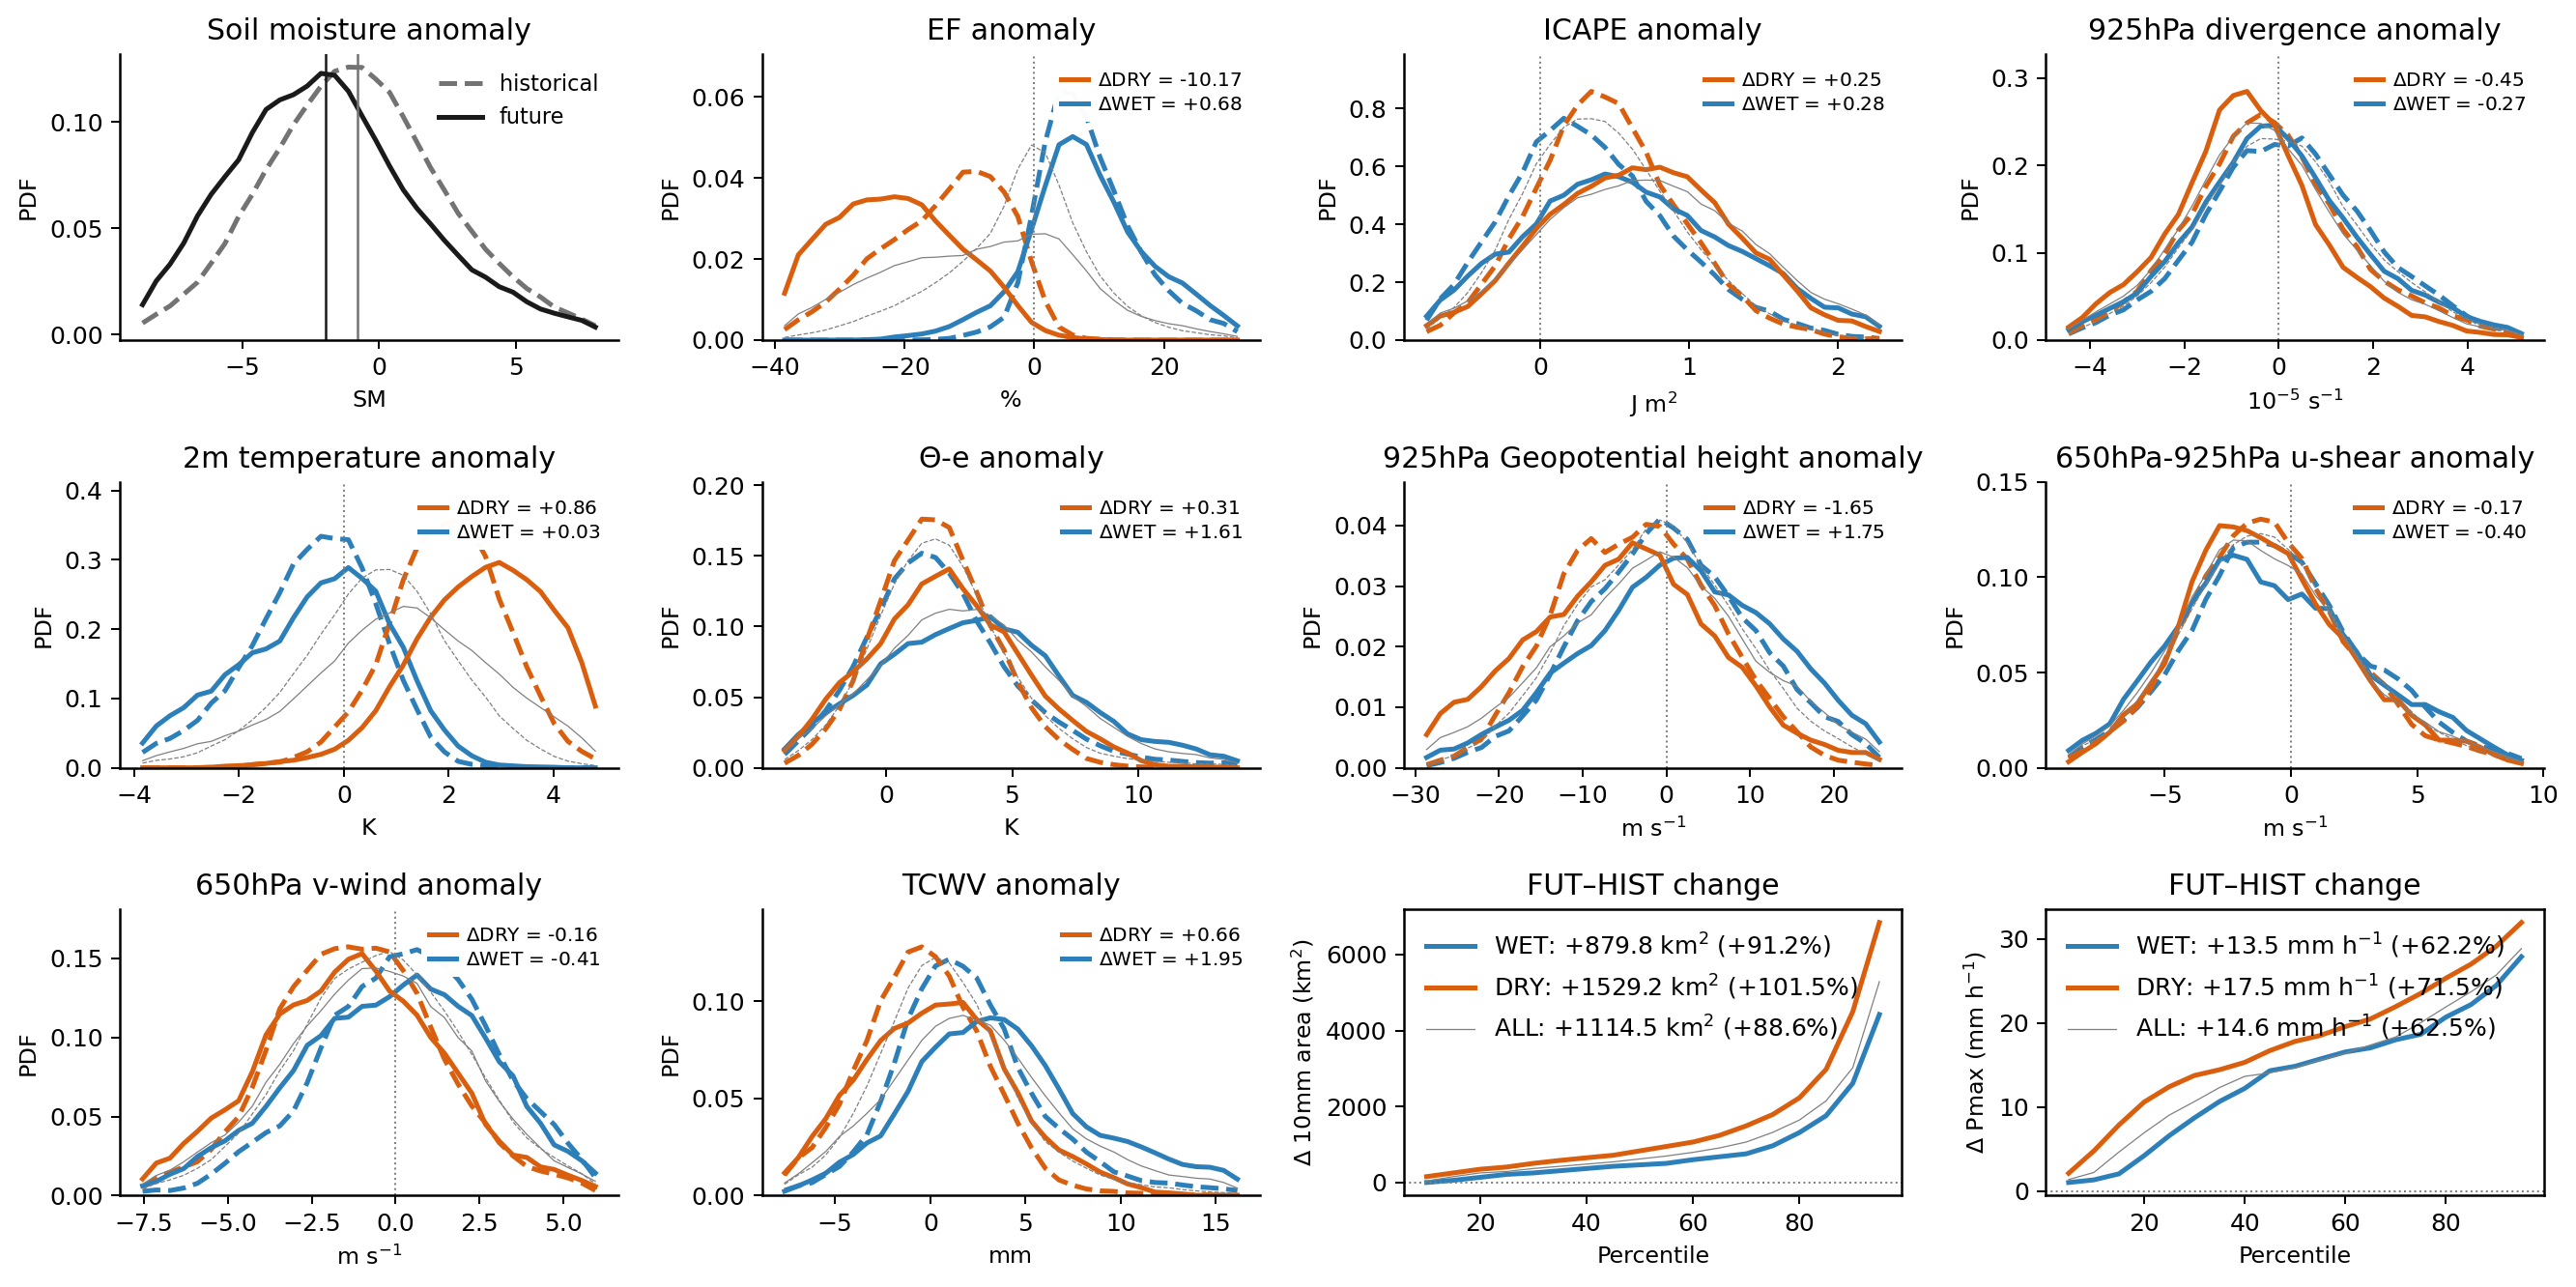

-0.5 -2
ef_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 72.33977592899174 50.60224726705177 69.36214426435 40.18916279230073
ICAPEfull_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 1.5136644313013368 1.695189084154328 2.5482763799313903 2.8035511948820284
div_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 0.17058074137705745 0.07918345931043032 -0.03655507634937859 -0.5727024541676041
t2_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 301.3395456133517 303.8987734690442 306.8173944446067 309.7908921604597
thetae_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 351.5842880299076 351.6240502718363 374.9797069115307 374.29406435810427
geoH_srfc_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): 780.3243860187816 779.2020335838363 795.8037938902594 791.6326337210074
shear_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -16.300394294375465 -16.770842856553628 -17.014158330976773 -18.040638389659453
v_mid_1deg absolute means (H-WET, H-DRY, F-WET, F-DRY): -1.4761600996686932 -

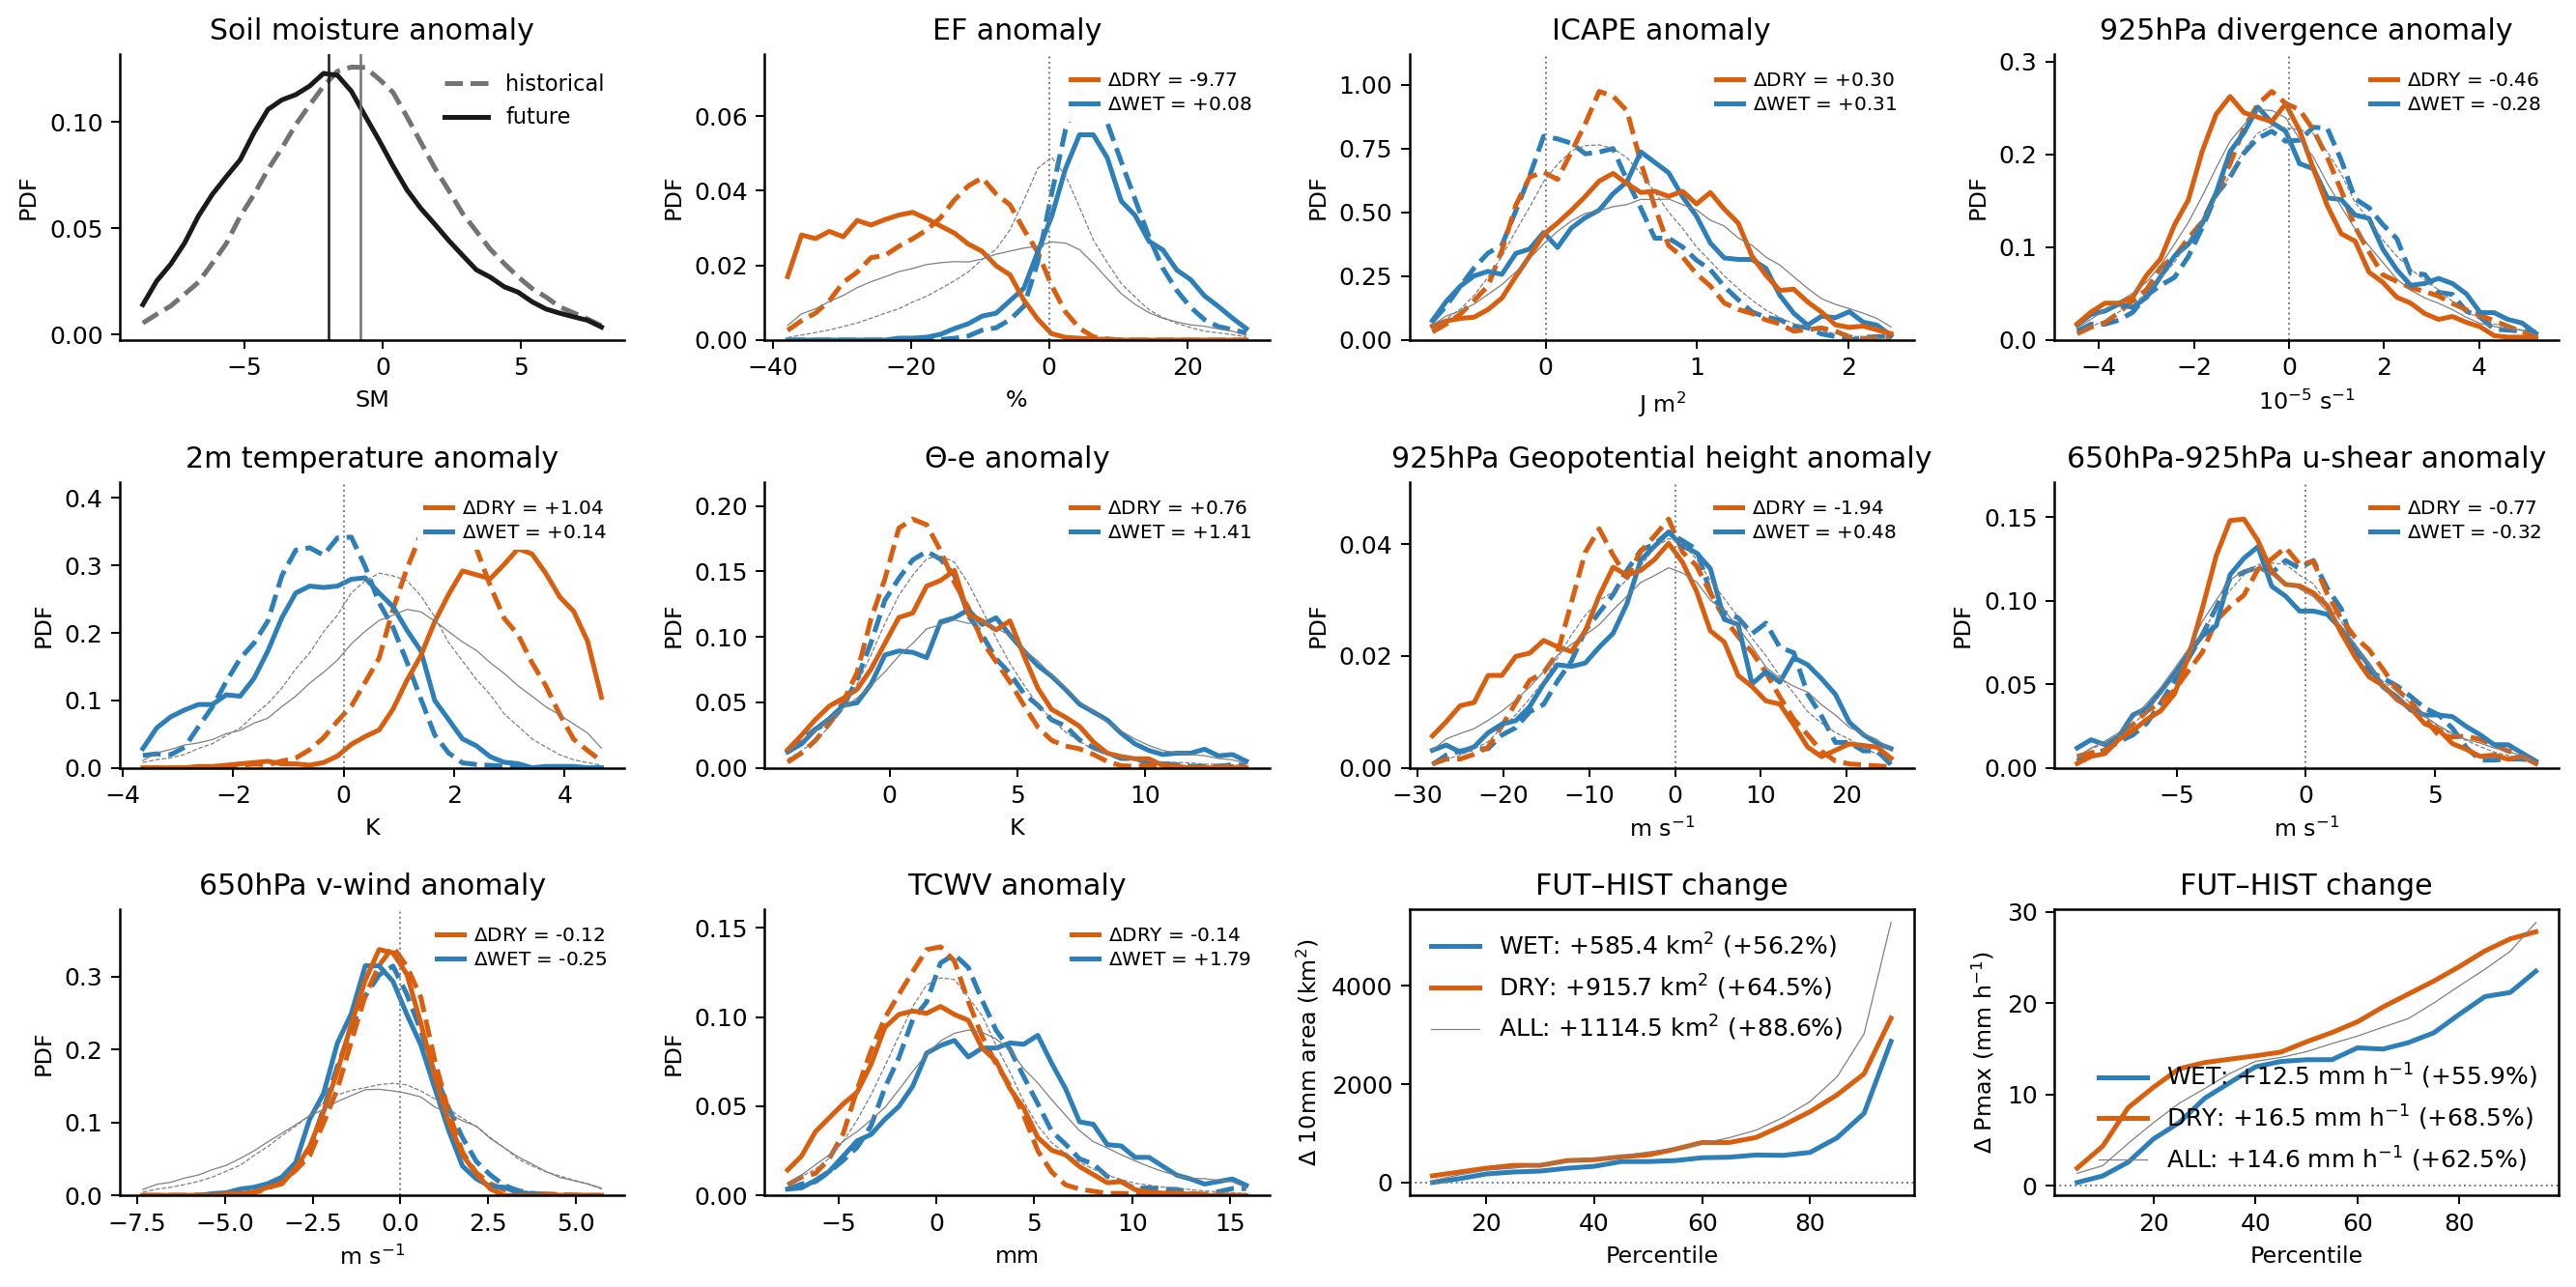

In [44]:
dtag = '1deg'

output_file1 = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/cp4_paper_ANOMALIES_PDFs_Sfig3_'+dtag+'.png'
output_file2 = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/cp4_paper_ANOMALIES_PDFs-vmid_Sfig4_'+dtag+'.png'

def plot_this(v_thresh_up=50, v_thresh_down=-50, output_file=output_file1):
    
    print(v_thresh_up, v_thresh_down)
    
    hist_north = (lhist['v_mid_fullBox'] < v_thresh_up) & (lhist['v_mid_fullBox'] > v_thresh_down)
    fut_north  = (lfut['v_mid_fullBox'] < v_thresh_up) & (lfut['v_mid_fullBox'] > v_thresh_down)
    
    histp25, histp75 = np.nanpercentile(lahist['SM_2deg'], [25, 75])
    futp25, futp75   = np.nanpercentile(lafut['SM_2deg'], [25, 75])
    
    histposlow  = (lahist['SM_2deg'] > histp75) & hist_north   # WET
    histposhigh = (lahist['SM_2deg'] < histp25) & hist_north   # DRY
    histall = lhist['pmax']>=1
    
    futposlow   = (lafut['SM_2deg'] > futp75) & fut_north    # WET
    futposhigh  = (lafut['SM_2deg'] < futp25) & fut_north    # DRY
    futall =  lfut['pmax']>=1

    
    
    # ------------------------------------------------------------
    # Colours / styles
    # ------------------------------------------------------------
    wet_col  = '#2C7FB8'
    dry_col  = '#D95F0E'
    hist_col = '0.45'
    fut_col  = '0.10'
    
    
    # ------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------
    def _clean(x, scale=1):
        x = np.asarray(x, dtype=float) * scale
        return x[np.isfinite(x)]
    
    def _smooth(y, n=3):
        if n <= 1:
            return y
        kernel = np.ones(n) / n
        return np.convolve(y, kernel, mode='same')
    
    def _make_bins(arrs, nbins=36, qrange=(1, 99)):
        zz = np.concatenate([a for a in arrs if len(a) > 0])
        lo, hi = np.nanpercentile(zz, qrange)
        return np.linspace(lo, hi, nbins + 1)
    
    def _pdf(vals, bins, smooth=3):
        h, edges = np.histogram(vals, bins=bins, density=True)
        mids = 0.5 * (edges[1:] + edges[:-1])
        return mids, _smooth(h, n=smooth)
    
    def style_ax(ax):
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(direction='out')
    
    def plot_sm_pdf(ax):
        hsm = _clean(lahist['SM_2deg'])
        fsm = _clean(lafut['SM_2deg'])
        bins = _make_bins([hsm, fsm], nbins=34, qrange=(1, 99))
    
        x, y = _pdf(hsm, bins, smooth=3)
        ax.plot(x, y, color=hist_col, ls='--', lw=2, label='historical')
    
        x, y = _pdf(fsm, bins, smooth=3)
        ax.plot(x, y, color=fut_col, ls='-', lw=2, label='future')
    
        # ax.axvline(histp25, color=hist_col, ls='--', lw=1)
        # ax.axvline(histp75, color=hist_col, ls='--', lw=1)
        # ax.axvline(futp25,  color=fut_col,  ls='-',  lw=1)
        # ax.axvline(futp75,  color=fut_col,  ls='-',  lw=1)
        ax.axvline(np.mean(lahist['SM_2deg']),  color=hist_col,  ls='-',  lw=1)
        ax.axvline(np.mean(lafut['SM_2deg']),  color=fut_col,  ls='-',  lw=1)
    
        ymax = ax.get_ylim()[1]
        # ax.text(histp25, ymax*0.95, 'H25', rotation=90, va='top', ha='right', fontsize=8, color=hist_col)
        # ax.text(histp75, ymax*0.95, 'H75', rotation=90, va='top', ha='right', fontsize=8, color=hist_col)
        # ax.text(futp25,  ymax*0.85, 'F25', rotation=90, va='top', ha='left',  fontsize=8, color=fut_col)
        # ax.text(futp75,  ymax*0.85, 'F75', rotation=90, va='top', ha='left',  fontsize=8, color=fut_col)
    
        ax.set_title('Soil moisture anomaly')
        ax.set_xlabel('SM')
        ax.set_ylabel('PDF')
        ax.legend(frameon=False, fontsize=9)
        style_ax(ax)
    
    
    def plot_group_pdf(ax, var, title, xlabel, scale=1, zero_line=False,
                       nbins=34, qrange=(1, 99), smooth=3, delta_decimals=2):
    
        # Absolute values for TCW, v-wind and ICAPE; anomalies otherwise
        absolute_vars = [] #'tcwv_'+dtag,  'ICAPEfull_'+dtag, 'shear_'+dtag, 'v_mid_'+dtag
        hdata, fdata = (lhist, lfut) if var in absolute_vars else (lahist, lafut)
    
        hwet = _clean(hdata.loc[histposlow, var], scale)
        hdry = _clean(hdata.loc[histposhigh, var], scale)
        fwet = _clean(fdata.loc[futposlow, var], scale)
        fdry = _clean(fdata.loc[futposhigh, var], scale)
        hall = _clean(hdata.loc[histall, var], scale)
        fall = _clean(fdata.loc[futall, var], scale)
    
        # Diagnostic: absolute environmental means, as in your original code
        absolute_means = [
            np.mean(_clean(data.loc[mask, var], scale))
            for data, mask in [(lhist, histposlow), (lhist, histposhigh),
                               (lfut, futposlow), (lfut, futposhigh)]
        ]
        print(var, 'absolute means (H-WET, H-DRY, F-WET, F-DRY):',
              *absolute_means)
    
        bins = _make_bins([hwet, hdry, fwet, fdry, hall, fall],
                          nbins, qrange)
    
        curves = [
            (hwet, wet_col, '--', 'hist-WET', 2),
            (hdry, dry_col, '--', 'hist-DRY', 2),
            (fwet, wet_col, '-', 'fut-WET', 2),
            (fdry, dry_col, '-', 'fut-DRY', 2),
            (hall, 'grey', '--', 'hist-ALL', 0.5),
            (fall, 'grey', '-', 'fut-ALL', 0.5)
        ]
    
        ymax = 0
    
        for vals, col, ls, lab, lw in curves:
            x, y = _pdf(vals, bins, smooth=smooth)
            ax.plot(x, y, color=col, ls=ls, lw=lw, label=lab)
            ymax = max(ymax, np.nanmax(y))

        ax.set_ylim(0, ymax * 1.15)
    
        # FUT minus HIST difference between group medians
        delta_dry = np.nanmedian(fdry) - np.nanmedian(hdry)
        delta_wet = np.nanmedian(fwet) - np.nanmedian(hwet)
    
        delta_handles = [
            Line2D([], [], color=dry_col, lw=2,
                   label=fr'$\Delta$DRY = {delta_dry:+.{delta_decimals}f}'),
            Line2D([], [], color=wet_col, lw=2,
                   label=fr'$\Delta$WET = {delta_wet:+.{delta_decimals}f}')
        ]
    
        delta_legend = ax.legend(
            handles=delta_handles,
            loc='upper right',
            frameon=True,
            framealpha=0.85,
            facecolor='white',
            edgecolor='none',
            fontsize=8,
            handlelength=1.4,
            handletextpad=0.5,
            borderpad=0.4,
            labelspacing=0.3
        )
    
        # Preserve this legend if another legend is subsequently added
        ax.add_artist(delta_legend)
    
        if zero_line:
            ax.axvline(0, color='0.5', ls=':', lw=0.8)
    
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('PDF')
        style_ax(ax)
    
    
    def _plot_change_panel(ax, var, pp, factor, unit, ylabel):
            groups = [('WET', histposlow, futposlow, '#2C7FB8', 2),
                      ('DRY', histposhigh, futposhigh, '#D95F0E', 2),
                      ('ALL', histall, futall, 'grey', 0.5)]
            
            for label, hmask, fmask, color, lw in groups:
                hist = np.nanpercentile(lahist.loc[hmask, var] * factor, pp)
                fut = np.nanpercentile(lafut.loc[fmask, var] * factor, pp)
                change = fut - hist
                absolute = np.mean(change)
                baseline = np.mean(hist)
                relative = 100 * absolute / baseline if baseline != 0 else np.nan
            
                legend = f'{label}: {absolute:+.1f} {unit} ({relative:+.1f}%)'
                ax.plot(pp, change, color=color, lw=lw, label=legend)
            
            ax.axhline(0, color='0.5', ls=':', lw=0.8)
            ax.set_xlabel('Percentile')
            ax.set_ylabel(ylabel)
            ax.set_title('FUT–HIST change')
            ax.legend(frameon=False)
    
    
    def plot_area_panel(ax):
            _plot_change_panel(ax, 'area_10mm', np.arange(10, 100, 5), 4.4**2,
                               r'km$^2$', r'$\Delta$ 10mm area (km$^2$)')
    
    
    def plot_pmax_panel(ax):
            _plot_change_panel(ax, 'pmax', np.arange(5, 100, 5), 1,
                               r'mm h$^{-1}$', r'$\Delta$ Pmax (mm h$^{-1}$)')
    
    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    fig, axs = plt.subplots(3,4, figsize=(15, 7.5), dpi=180)
    axs = axs.ravel()
    
    # 1) full SM distribution
    plot_sm_pdf(axs[0])
    
    # 2-6) associated environmental variables
    plot_group_pdf(axs[1], 'ef_'+dtag,   'EF anomaly',         '%', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[2], r'ICAPEfull_'+dtag,   'ICAPE anomaly',       r'J m$^{2}$', scale=1e-6, zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[3], 'div_'+dtag,  '925hPa divergence anomaly',     r'$10^{-5}$ s$^{-1}$', scale=1e5, zero_line=True, nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[4], 't2_'+dtag,   r'2m temperature anomaly',       'K', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[5], r'thetae_'+dtag,   '$\Theta$-e anomaly','K',         zero_line=False, nbins=34, qrange=(1, 99))
    
                   
    
    # 7-8) storm characteristics
    plot_group_pdf(axs[6], r'geoH_srfc_'+dtag, r'925hPa Geopotential height anomaly', r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[7], r'shear_'+dtag, r'650hPa-925hPa u-shear anomaly', r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[8], r'v_mid_'+dtag, r'650hPa v-wind anomaly',       r'm s$^{-1}$', zero_line=True,  nbins=34, qrange=(1, 99))
    plot_group_pdf(axs[9], 'tcwv_'+dtag,'TCWV anomaly','mm',         zero_line=False, nbins=34, qrange=(1, 99))
    
                   
    
    # 7-8) storm characteristics
    plot_area_panel(axs[10])
    plot_pmax_panel(axs[11])
    
    plt.tight_layout()
    fig.savefig(output_file, dpi=200)
    plt.show()


plot_this(v_thresh_up=50, v_thresh_down=-50, output_file=output_file1)
plot_this(v_thresh_up=-0.5, v_thresh_down=-2, output_file=output_file2)

Climate-specific SM thresholds: -3.069373148619687 1.2701124875938048 -4.469566451840368 0.1544570948576085
Sample sizes (H-WET, H-DRY, F-WET, F-DRY): 4748 4877 3322 3515
SM anomaly: HIST thresholds -3.10, 1.24; DRY 25.0% -> 40.2%; WET 25.0% -> 16.7%
EF anomaly: HIST thresholds -6.69, 4.08; DRY 25.0% -> 45.9%; WET 25.0% -> 22.3%


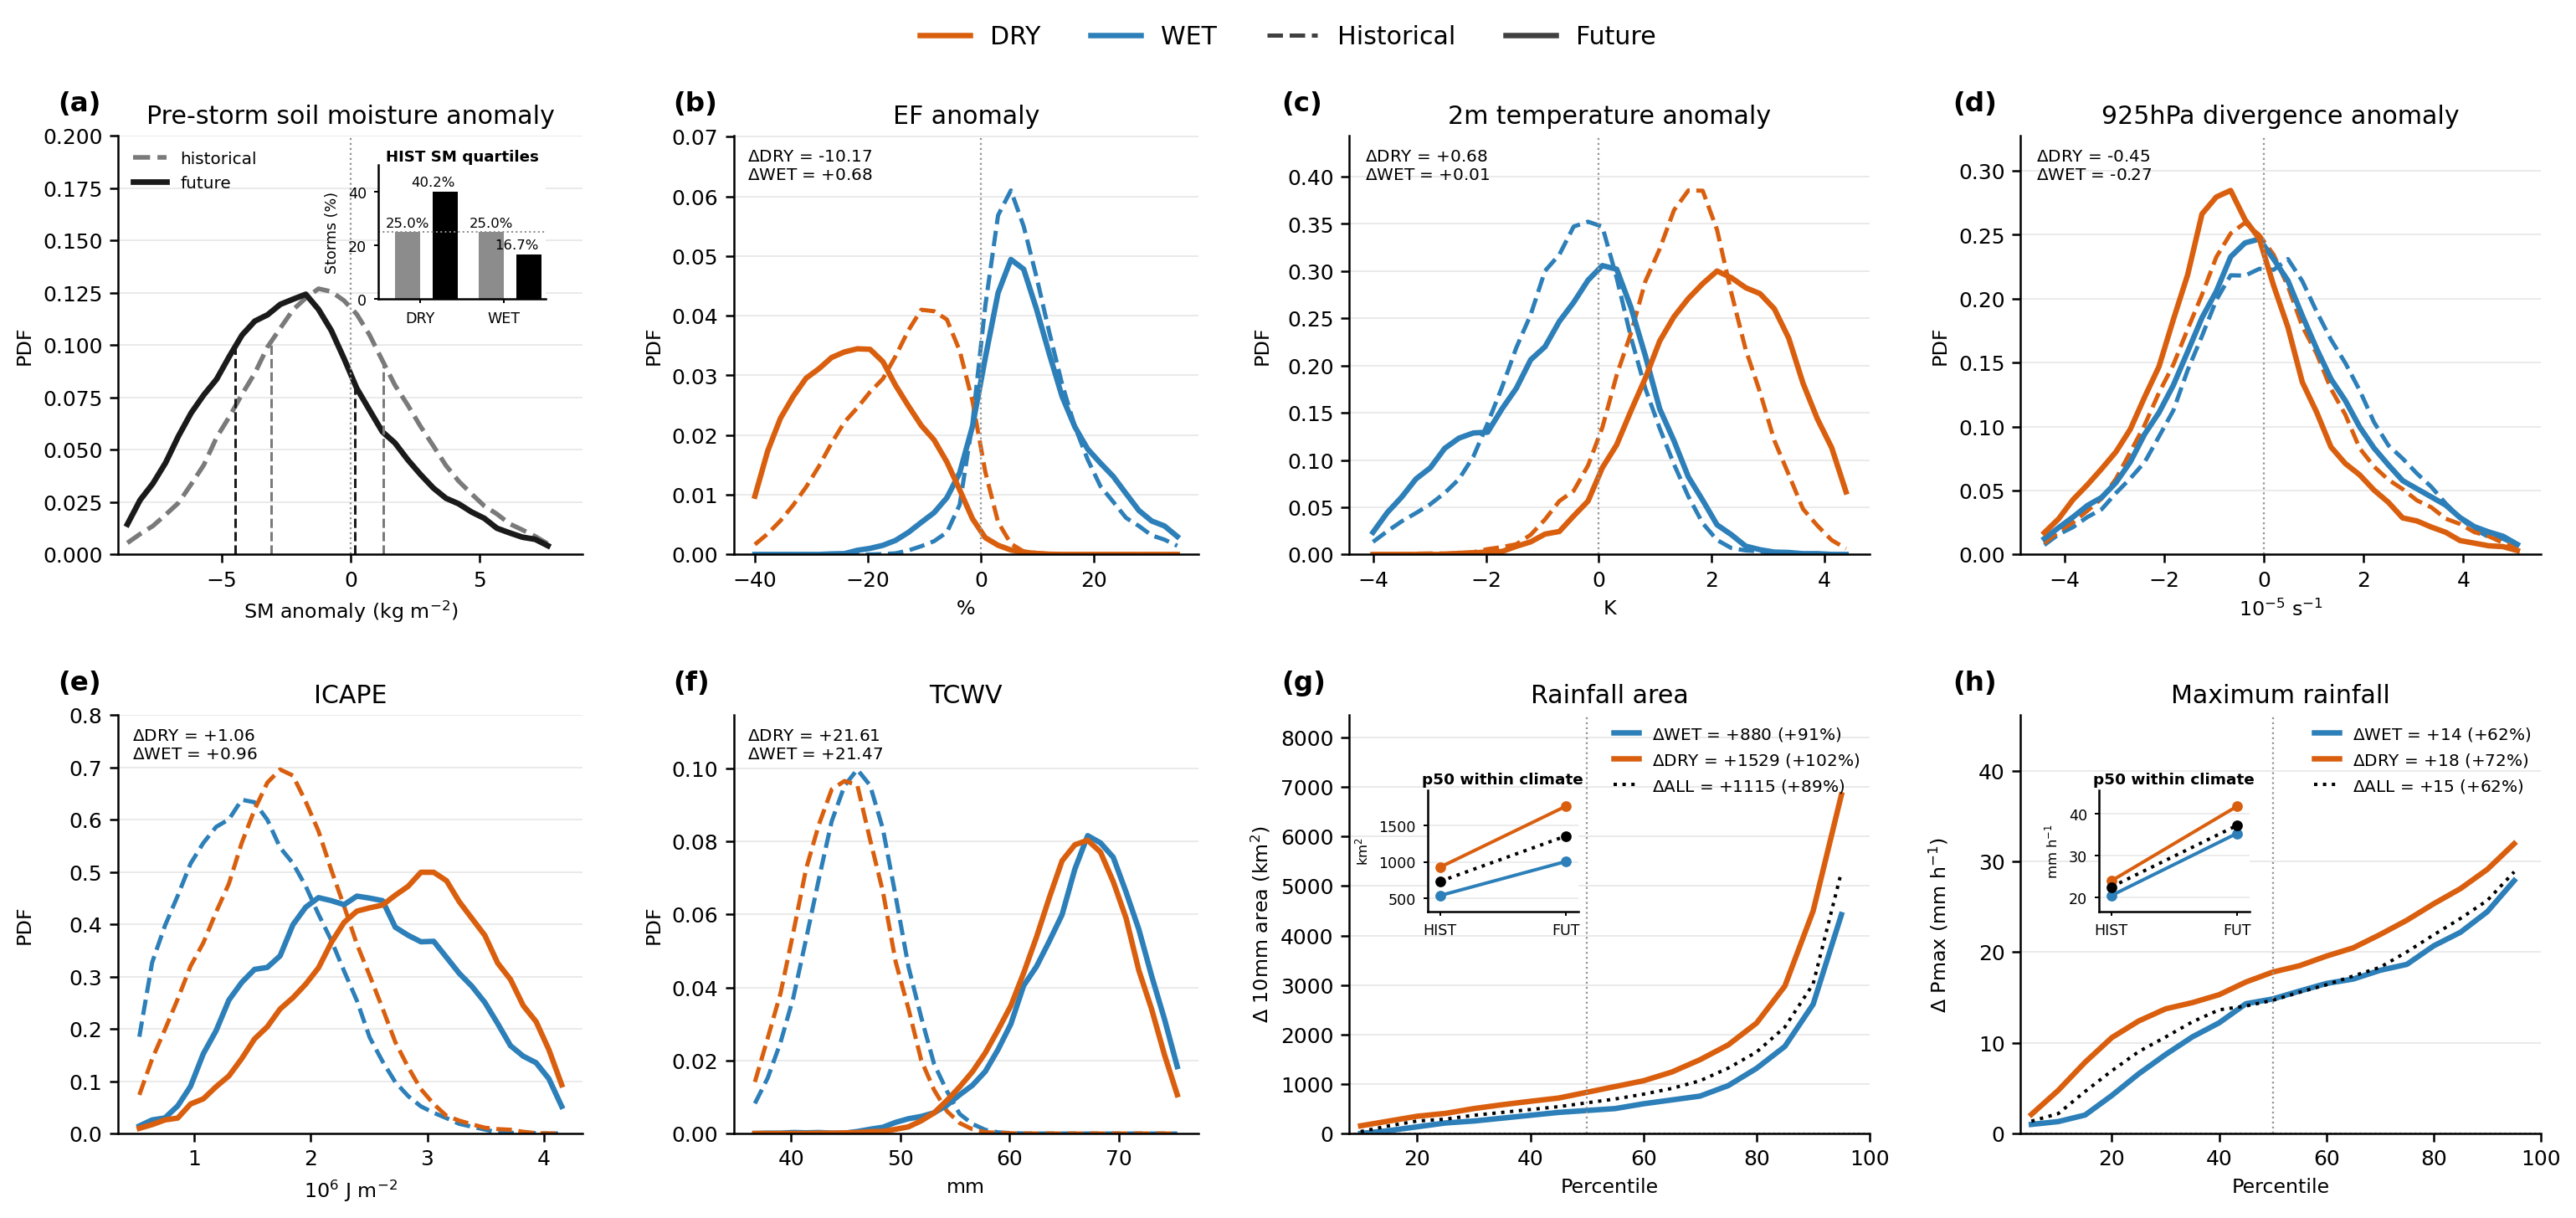

In [47]:
dtag = '1deg'
v_thresh_up, v_thresh_down = 50, -50
area_thresh, grid_km = 500000, 4.4
summary_percentile = 50

output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/fig2_PDFs_'+dtag+'.jpg'

# (variable, title, x label, source, scale, zero line, decimals)
PDF_PANELS = {
    'ef':    ('ef_'+dtag,        'EF anomaly', '%', 'anom', 1,    True,  2),
    't2':    ('t_srfc_'+dtag,    '2m temperature anomaly',      'K', 'anom', 1,    True,  2),
    'div':   ('div_'+dtag,       '925hPa divergence anomaly',   r'$10^{-5}$ s$^{-1}$', 'anom', 1e5, True, 2),
    'icape': ('ICAPEfull_'+dtag, 'ICAPE', r'$10^{6}$ J m$^{-2}$', 'abs', 1e-6, False, 2),
    'tcwv':  ('tcwv_'+dtag,      'TCWV',    'mm', 'abs', 1,    False, 2),
}
AREA_VAR, PMAX_VAR = 'area_10mm', 'pmax'
AREA_PP = np.unique(np.r_[np.arange(10, 100, 5), summary_percentile])
PMAX_PP = np.unique(np.r_[np.arange(5, 100, 5), summary_percentile])

# Plot appearance
wet_col, dry_col, all_col = '#2C7FB8', '#D95F0E', '0.48'
hist_col, fut_col = '0.48', '0.10'
pdf_opts = dict(nbins=34, qrange=(1, 99), smooth=3)


# =============================================================================
# SM SPLIT AND SAMPLING FILTERS
# =============================================================================
# Climate-specific SM-anomaly thresholds from the full tables, BEFORE filtering.
histp25, histp75 = np.nanpercentile(lahist['SM_2deg'], [25, 75])
futp25, futp75 = np.nanpercentile(lafut['SM_2deg'], [25, 75])

# Additional sampling filters, applied after defining the thresholds.
hist_north = (lhist['v_mid_fullBox'] < v_thresh_up) & (lhist['v_mid_fullBox'] > v_thresh_down)
fut_north = (lfut['v_mid_fullBox'] < v_thresh_up) & (lfut['v_mid_fullBox'] > v_thresh_down)
hist_area = lhist['area'] * grid_km**2 < area_thresh
fut_area = lfut['area'] * grid_km**2 < area_thresh
hist_split_sample, fut_split_sample = hist_north & hist_area, fut_north & fut_area

histposlow = (lahist['SM_2deg'] > histp75) & hist_split_sample   # WET
histposhigh = (lahist['SM_2deg'] < histp25) & hist_split_sample  # DRY
futposlow = (lafut['SM_2deg'] > futp75) & fut_split_sample       # WET
futposhigh = (lafut['SM_2deg'] < futp25) & fut_split_sample      # DRY

# ALL uses the area filter only, matching the other code.
histall, futall = hist_area, fut_area

print('Climate-specific SM thresholds:', histp25, histp75, futp25, futp75)
print('Sample sizes (H-WET, H-DRY, F-WET, F-DRY):',
      histposlow.sum(), histposhigh.sum(), futposlow.sum(), futposhigh.sum())


# =============================================================================
# HELPERS
# =============================================================================
def _clean(x, scale=1):
    x = np.asarray(x, dtype=float) * scale
    return x[np.isfinite(x)]


def _smooth(y, n=3):
    return y if n <= 1 else np.convolve(y, np.ones(n) / n, mode='same')


def _make_bins(arrs, nbins=36, qrange=(1, 99)):
    pooled = np.concatenate([a for a in arrs if len(a) > 0])
    lo, hi = np.nanpercentile(pooled, qrange)
    return np.linspace(lo, hi, nbins + 1)


def _pdf(vals, bins, smooth=3):
    hist, edges = np.histogram(vals, bins=bins, density=True)
    return 0.5 * (edges[1:] + edges[:-1]), _smooth(hist, smooth)


def style_ax(ax, zero_y=False):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', labelsize=10, width=1, length=4)
    ax.grid(axis='y', color='0.91', lw=0.7, zorder=0)
    if zero_y:
        ax.axhline(0, color='0.55', ls=':', lw=0.9, zorder=0)


def panel_label(ax, label):
    ax.text(-0.13, 1.045, f'({label})', transform=ax.transAxes,
            ha='left', va='bottom', fontsize=13, fontweight='semibold',
            color='black', clip_on=False)


def fixed_frequency(hist, fut, var, hmask, fmask):
    """Shares outside fixed historical quartile thresholds."""
    h, f = _clean(hist.loc[hmask, var]), _clean(fut.loc[fmask, var])
    q25, q75 = np.nanpercentile(h, [25, 75])
    out = {'q25': q25, 'q75': q75,
           'hist_dry': 100*np.mean(h < q25), 'fut_dry': 100*np.mean(f < q25),
           'hist_wet': 100*np.mean(h > q75), 'fut_wet': 100*np.mean(f > q75)}
    return out


# Basic frequency statistics for text/reporting.
sm_frequency = fixed_frequency(lahist, lafut, 'SM_2deg',
                               hist_split_sample, fut_split_sample)
ef_frequency = fixed_frequency(lahist, lafut, 'ef_2deg',
                               hist_split_sample, fut_split_sample)
for name, stat in [('SM anomaly', sm_frequency), ('EF anomaly', ef_frequency)]:
    print(f"{name}: HIST thresholds {stat['q25']:.2f}, {stat['q75']:.2f}; "
          f"DRY {stat['hist_dry']:.1f}% -> {stat['fut_dry']:.1f}%; "
          f"WET {stat['hist_wet']:.1f}% -> {stat['fut_wet']:.1f}%")


# =============================================================================
# PDF PANELS
# =============================================================================
def plot_sm_pdf(ax):
    """Full SM anomaly PDF plus frequency under fixed historical thresholds."""
    hs = _clean(lahist.loc[hist_split_sample, 'SM_2deg'])
    fs = _clean(lafut.loc[fut_split_sample, 'SM_2deg'])
    bins = _make_bins([hs, fs], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})
    
    hx, hy = _pdf(hs, bins, pdf_opts['smooth'])
    fx, fy = _pdf(fs, bins, pdf_opts['smooth'])
    
    ax.plot(hx, hy, color=hist_col, ls='--', lw=2.2, label='historical')
    ax.plot(fx, fy, color=fut_col,  ls='-',  lw=2.7, label='future')
    
    for q in [histp25, histp75]:
        ax.vlines(q, 0, np.interp(q, hx, hy),
                  color=hist_col, ls='--', lw=1.2)
    
    for q in [futp25, futp75]:
        ax.vlines(q, 0, np.interp(q, fx, fy),
                  color=fut_col, ls='--', lw=1.2)

    
    ax.axvline(0, color='0.58', ls=':', lw=0.9)
    
    ax.set(title='Pre-storm soil moisture anomaly',
           xlabel=r'SM anomaly (kg m$^{-2}$)', ylabel='PDF')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
    ax.set_ylim(0,0.2)
    ax.set_xlim(-9,9)
    
    style_ax(ax)

    # Compact inset: future share in historically DRY/WET anomaly classes.
    iax = ax.inset_axes([0.56, 0.61, 0.36, 0.32])
    vals = np.array([[sm_frequency['hist_dry'], sm_frequency['hist_wet']],
                     [sm_frequency['fut_dry'], sm_frequency['fut_wet']]])
    xx, width = np.arange(2), 0.3
    iax.bar(xx-width/2, vals[0], width, color='0.55')
    iax.bar(xx+width+0.001/2, vals[1], width, color='k')
    for off, row in zip([-width/2, width/2], vals):
        for xpos, value in zip(xx+off, row):
            iax.text(xpos, value+1, f'{value:.1f}%', ha='center', va='bottom', fontsize=6.6)
    iax.axhline(25, color='0.55', ls=':', lw=0.8)
    iax.set_xticks(xx, ['DRY', 'WET'], fontsize=7)
    iax.set_ylim(0, max(50, vals.max()*1.18))

    iax.set_xlim(-0.5, 1.5)
    
    iax.set_ylabel('Storms (%)', fontsize=7)
    iax.set_title('HIST SM quartiles', fontsize=7.3, pad=2, fontweight='bold')
    iax.tick_params(labelsize=7, length=2)
    iax.spines[['top', 'right']].set_visible(False)

    


def plot_group_pdf(ax, key):
    var, title, xlabel, source, scale, zero_line, decimals = PDF_PANELS[key]
    hdata, fdata = (lhist, lfut) if source == 'abs' else (lahist, lafut)
    hwet, hdry = _clean(hdata.loc[histposlow, var], scale), _clean(hdata.loc[histposhigh, var], scale)
    fwet, fdry = _clean(fdata.loc[futposlow, var], scale), _clean(fdata.loc[futposhigh, var], scale)
    bins = _make_bins([hwet, hdry, fwet, fdry], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})

    ymax = 0

    for vals, col, ls, lw in [(hwet, wet_col, '--', 2), (hdry, dry_col, '--', 2),
                              (fwet, wet_col, '-', 2.6), (fdry, dry_col, '-', 2.6)]:
        x, y = _pdf(vals, bins, pdf_opts['smooth'])
        ax.plot(x, y, color=col, ls=ls, lw=lw)
        ymax = max(ymax, np.nanmax(y))

    ax.set_ylim(0, ymax * 1.15)

    ddry = np.nanmedian(fdry) - np.nanmedian(hdry)
    dwet = np.nanmedian(fwet) - np.nanmedian(hwet)

    ax.text(0.03, 0.97,
            fr'$\Delta$DRY = {ddry:+.{decimals}f}' + '\n' +
            fr'$\Delta$WET = {dwet:+.{decimals}f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=8)

    if zero_line:
        ax.axvline(0, color='0.58', ls=':', lw=0.9)

    ax.set(title=title, xlabel=xlabel, ylabel='PDF')
    style_ax(ax)


# =============================================================================
# STORM-RESPONSE PANELS AND WITHIN-CLIMATE Q99 INSETS
# =============================================================================
def _groups(hdata, fdata, var, factor):
    return {
        'WET': (_clean(hdata.loc[histposlow, var], factor), _clean(fdata.loc[futposlow, var], factor), wet_col, 2.6, '-'),
        'DRY': (_clean(hdata.loc[histposhigh, var], factor), _clean(fdata.loc[futposhigh, var], factor), dry_col, 2.6, '-'),
        'ALL': (_clean(hdata[var], factor),_clean(fdata[var], factor),'k', 1.6, ':'),
    }


def _baseline_inset(ax, groups, percentile, unit):
    """Actual quantiles; vertical DRY/WET gaps are within-climate differences."""
    iax = ax.inset_axes([0.15, 0.53, 0.29, 0.29], zorder=5)
    iax.set_facecolor('white')
    qvals = {}
    for label, (hist, fut, colour, lw, ls) in groups.items():
        qh, qf = np.nanpercentile(hist, percentile), np.nanpercentile(fut, percentile)
        qvals[label] = (qh, qf)
        iax.plot([0, 1], [qh, qf], color=colour, marker='o', ms=4.1, lw=1.6, ls=ls)
    hgap = qvals['DRY'][0]-qvals['WET'][0]
    fgap = qvals['DRY'][1]-qvals['WET'][1]
    iax.set_title(fr'p{percentile:g} within climate', fontsize=7.4, pad=3,
                  fontweight='semibold')
    #iax.text(0.5, 0.84, fr'DRY$-$WET: H {hgap:+.1f}; F {fgap:+.1f}',
    #         transform=iax.transAxes, ha='center', va='top', fontsize=6.6)
    iax.set_xticks([0, 1], ['HIST', 'FUT'])
    iax.set_ylabel(unit, fontsize=6.6)
    iax.margins(x=0.10, y=0.18)
    iax.tick_params(labelsize=7, length=2)
    iax.grid(axis='y', color='0.9', lw=0.6)
    iax.spines[['top', 'right']].set_visible(False)


def plot_change_panel(ax, var, pp, factor, unit, ylabel, title):
    # Storm properties are held in the anomaly tables in the current workflow.
    groups = _groups(lahist, lafut, var, factor)
    for label, (hist, fut, colour, lw,ls) in groups.items():
        hq, fq = np.nanpercentile(hist, pp), np.nanpercentile(fut, pp)
        change = fq-hq
        absolute, baseline = np.mean(change), np.mean(hq)
        relative = 100*absolute/baseline if baseline != 0 else np.nan
        ax.plot(pp, change, color=colour, lw=lw, ls=ls,
                label=fr'$\Delta${label} = {absolute:+.0f} ({relative:+.0f}%)')
    ax.axhline(0, color='0.55', ls=':', lw=0.9)
    ax.set(title=title, xlabel='Percentile', ylabel=ylabel, xlim=(pp.min()-2, 100))
    ax.legend(frameon=False, fontsize=8, loc='upper right',
              handlelength=1.5, borderaxespad=0.2)

    ax.set_ylim(0,np.max(change)+np.max(change)*0.6)
    ax.axvline(50, color='0.58', ls=':', lw=0.9)
    
    _baseline_inset(ax, groups, summary_percentile, unit)
    style_ax(ax)


# =============================================================================
# BUILD FIGURE
# =============================================================================
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12,
                     'axes.titleweight': 'normal', 'axes.labelsize': 9.5,
                     'axes.linewidth': 1.0, 'savefig.bbox': 'tight'})

fig, axs = plt.subplots(2, 4, figsize=(17.2, 8.0), dpi=180,
                        gridspec_kw={'width_ratios': [1, 1, 1.12, 1.12]})

# Top: land-effect chain
plot_sm_pdf(axs[0, 0])
plot_group_pdf(axs[0, 1], 'ef')
plot_group_pdf(axs[0, 2], 't2')
plot_group_pdf(axs[0, 3], 'div')

# Bottom: thermodynamic state and MCS response
plot_group_pdf(axs[1, 0], 'icape')
plot_group_pdf(axs[1, 1], 'tcwv')
plot_change_panel(axs[1, 2], AREA_VAR, AREA_PP, grid_km**2, r'km$^2$',
                  r'$\Delta$ 10mm area (km$^2$)', 'Rainfall area')
plot_change_panel(axs[1, 3], PMAX_VAR, PMAX_PP, 1, r'mm h$^{-1}$',
                  r'$\Delta$ Pmax (mm h$^{-1}$)', 'Maximum rainfall')

for label, ax in zip('abcdefgh', axs.flat):
    panel_label(ax, label)

# One compact key for the repeated state/line encoding.
handles = [Line2D([], [], color=dry_col, lw=2.6, label='DRY'),
           Line2D([], [], color=wet_col, lw=2.6, label='WET'),
           Line2D([], [], color='0.25', ls='--', lw=2, label='Historical'),
           Line2D([], [], color='0.25', ls='-', lw=2.6, label='Future')]
fig.legend(handles=handles, frameon=False, ncol=4, loc='upper center',
           bbox_to_anchor=(0.5, 1.015), fontsize=12)

fig.align_ylabels(axs)
plt.tight_layout(rect=(0, 0, 1, 0.96), w_pad=1.8, h_pad=2.2)

fig.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()


In [48]:
p25, p75 = histp25, histp75

def soil_groups(df, eligible):
    sm = df['SM_2deg']
    return {
        'DRY': eligible & (sm < p25),
        'MID': eligible & (sm >= p25) & (sm <= p75),
        'WET': eligible & (sm > p75)
    }

def decompose_mean_change(var, factor=1):
    hg = soil_groups(lahist, hist_split_sample)
    fg = soil_groups(lafut, fut_split_sample)
    rows = []

    nh = hist_split_sample.sum()
    nf = fut_split_sample.sum()

    for group in ['DRY', 'MID', 'WET']:
        ph = hg[group].sum() / nh
        pf = fg[group].sum() / nf

        mh = np.nanmean(lahist.loc[hg[group], var] * factor)
        mf = np.nanmean(lafut.loc[fg[group], var] * factor)

        frequency = (pf-ph) * (mf+mh) / 2
        within_state = (mf-mh) * (pf+ph) / 2
        contribution = frequency + within_state

        rows.append([group, ph, pf, mh, mf,
                     frequency, within_state, contribution])

    out = pd.DataFrame(rows, columns=[
        'group', 'fraction_hist', 'fraction_fut',
        'mean_hist', 'mean_fut',
        'frequency_effect', 'within_state_effect',
        'total_contribution'
    ])

    # Same eligible population as used for the decomposition
    hmean = np.nanmean(lahist.loc[hist_split_sample, var] * factor)
    fmean = np.nanmean(lafut.loc[fut_split_sample, var] * factor)
    total_change = fmean - hmean

    out['fraction_of_total_change_%'] = 100 * out['total_contribution'] / total_change

    print(f'\nTotal mean change: {total_change:.3f}')
    print(f'Sum of contributions: {out.total_contribution.sum():.3f}')
    print(out)

    return out

pmax_decomp = decompose_mean_change('pmax')
area_decomp = decompose_mean_change('area_10mm', factor=4.4**2)


Total mean change: 14.287
Sum of contributions: 14.287
  group  fraction_hist  fraction_fut  mean_hist   mean_fut  frequency_effect  \
0   DRY       0.253259      0.406589  24.770402  40.789609          5.026187   
1   MID       0.500182      0.427661  23.328570  35.591673         -2.136467   
2   WET       0.246560      0.165749  22.081815  35.402309         -2.322653   

   within_state_effect  total_contribution  fraction_of_total_change_%  
0             5.285121           10.311307                   72.170712  
1             5.689116            3.552650                   24.865640  
2             2.746081            0.423428                    2.963649  

Total mean change: 1301.943
Sum of contributions: 1301.943
  group  fraction_hist  fraction_fut    mean_hist     mean_fut  \
0   DRY       0.253259      0.406589  1695.089670  3217.931968   
1   MID       0.500182      0.427661  1385.110316  2446.548703   
2   WET       0.246560      0.165749  1102.276361  2058.241188   

   fre

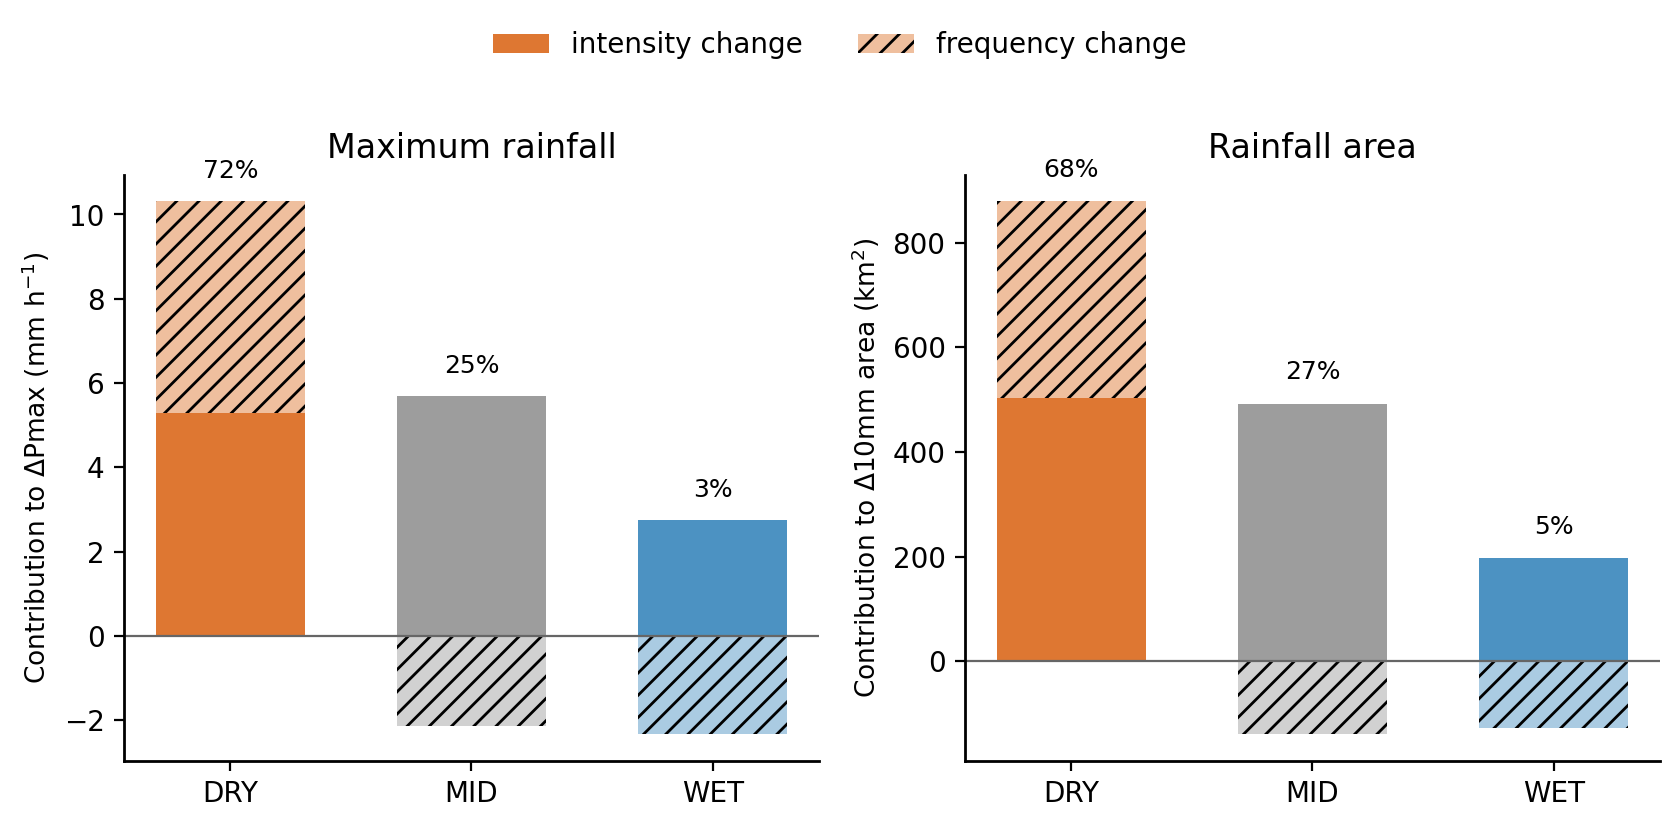

In [49]:
output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/mean_contribution_SFig_'+dtag+'.jpg'

dry_col, wet_col = '#D95F0E', '#2C7FB8'
group_cols = [dry_col, '0.55', wet_col]

def contribution_panel(ax, df, ylabel, title):
    x = np.arange(3)
    freq = df['frequency_effect'].values
    within = df['within_state_effect'].values
    total = df['total_contribution'].values
    pct = df['fraction_of_total_change_%'].values

    # Within-state contribution
    ax.bar(x, within, width=0.62, color=group_cols, alpha=0.85,
           label='intensity change')

    # Frequency contribution: stack positive values, show negative below zero
    pos = freq >= 0
    ax.bar(x[pos], freq[pos], width=0.62, bottom=within[pos],
           color=np.array(group_cols)[pos], alpha=0.40,
           hatch='///', label='frequency change')
    ax.bar(x[~pos], freq[~pos], width=0.62,
           color=np.array(group_cols)[~pos], alpha=0.40, hatch='///')

    ax.axhline(0, color='0.4', lw=0.8)

    for i, (tot, pc) in enumerate(zip(total, pct)):
        y = max(within[i] + max(freq[i], 0), within[i])
        ax.text(i, y + 0.04*ax.get_ylim()[1],
                f'{pc:.0f}%', ha='center', va='bottom', fontsize=9)

    ax.set_xticks(x, ['DRY', 'MID', 'WET'])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)


fig, axs = plt.subplots(1, 2, figsize=(8.5, 4), dpi=200)

contribution_panel(
    axs[0], pmax_decomp,
    r'Contribution to $\Delta$Pmax (mm h$^{-1}$)',
    'Maximum rainfall'
)

contribution_panel(
    axs[1], area_decomp,
    r'Contribution to $\Delta$10mm area (km$^2$)',
    'Rainfall area'
)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2,
           loc='upper center', bbox_to_anchor=(0.5, 1.04))

plt.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(output_file, dpi=300, bbox_inches='tight')

plt.show()

Climate-specific SM thresholds: -3.1010024411858588 1.2378561807494246 -4.519788014882209 0.02833149307439095
Sample sizes (H-WET, H-DRY, F-WET, F-DRY): 4814 4814 2313 5551
SM anomaly: HIST thresholds -3.10, 1.24; DRY 25.0% -> 40.2%; WET 25.0% -> 16.7%
EF anomaly: HIST thresholds -6.69, 4.08; DRY 25.0% -> 45.9%; WET 25.0% -> 22.3%
ef_2deg 75
t_srfc_2deg 75
div_2deg 25
ICAPEfull_2deg 75
tcwv_2deg 75


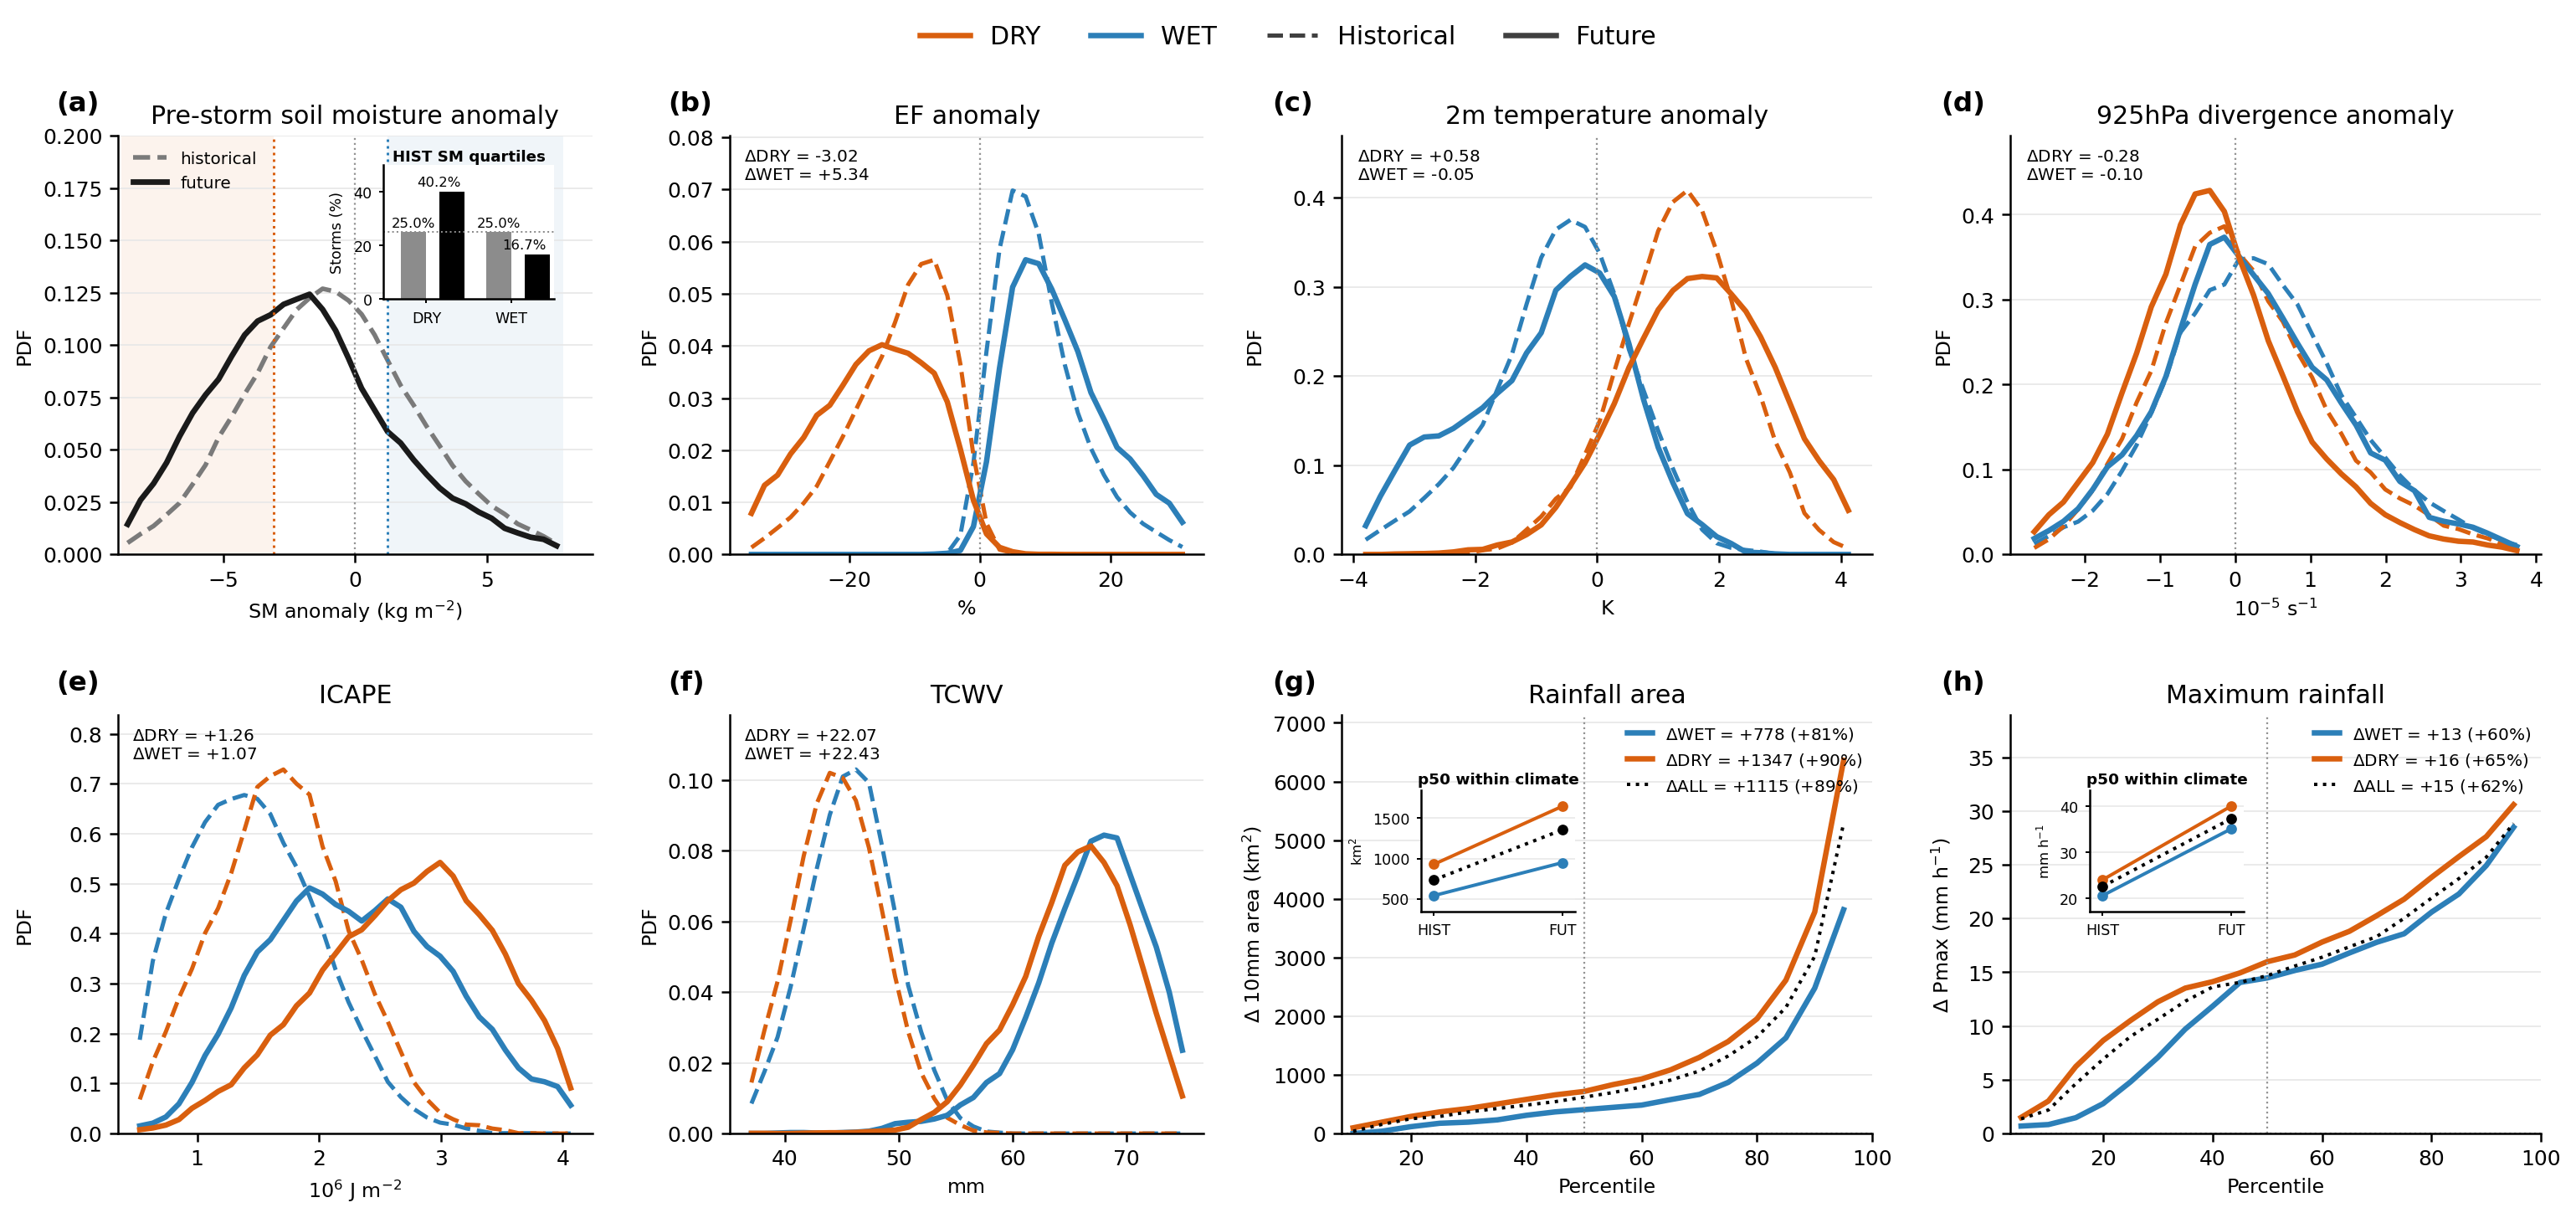

In [50]:
dtag = '2deg'
v_thresh_up, v_thresh_down = 50, -50
area_thresh, grid_km = 500000, 4.4
summary_percentile = 50

output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/fig2_PDFs_'+dtag+'_histSMquartiles.jpg'

# (variable, title, x label, source, scale, zero line, decimals)
PDF_PANELS = {
    'ef':    ('ef_'+dtag,        'EF anomaly', '%', 'anom', 1,    True,  2),
    't2':    ('t_srfc_'+dtag,    '2m temperature anomaly',      'K', 'anom', 1,    True,  2),
    'div':   ('div_'+dtag,       '925hPa divergence anomaly',   r'$10^{-5}$ s$^{-1}$', 'anom', 1e5, True, 2),
    'icape': ('ICAPEfull_'+dtag, 'ICAPE', r'$10^{6}$ J m$^{-2}$', 'abs', 1e-6, False, 2),
    'tcwv':  ('tcwv_'+dtag,      'TCWV',    'mm', 'abs', 1,    False, 2),
}
AREA_VAR, PMAX_VAR = 'area_10mm', 'pmax'
AREA_PP = np.unique(np.r_[np.arange(10, 100, 5), summary_percentile])
PMAX_PP = np.unique(np.r_[np.arange(5, 100, 5), summary_percentile])

# Plot appearance
wet_col, dry_col, all_col = '#2C7FB8', '#D95F0E', '0.48'
hist_col, fut_col = '0.48', '0.10'
pdf_opts = dict(nbins=34, qrange=(1, 99), smooth=3)


# =============================================================================
# SM SPLIT AND SAMPLING FILTERS
# =============================================================================
hist_north = (lhist['v_mid_fullBox'] < v_thresh_up) & (lhist['v_mid_fullBox'] > v_thresh_down)
fut_north = (lfut['v_mid_fullBox'] < v_thresh_up) & (lfut['v_mid_fullBox'] > v_thresh_down)
hist_area = lhist['area'] * grid_km**2 < area_thresh
fut_area = lfut['area'] * grid_km**2 < area_thresh

# Use the same eligible sample for the percentile thresholds and DRY/WET masks.
hist_split_sample, fut_split_sample = hist_north & hist_area, fut_north & fut_area
histp25, histp75 = np.nanpercentile(lahist.loc[hist_split_sample, 'SM_2deg'], [25, 75])
futp25, futp75 = np.nanpercentile(lafut.loc[fut_split_sample, 'SM_2deg'], [25, 75])

histposlow = (lahist['SM_2deg'] > histp75) & hist_split_sample    # WET
histposhigh = (lahist['SM_2deg'] < histp25) & hist_split_sample  # DRY
futposlow = (lafut['SM_2deg'] > histp75) & fut_split_sample       # WET
futposhigh = (lafut['SM_2deg'] < histp25) & fut_split_sample      # DRY

# Preserve the original ALL selection for storm-response curves.
histall, futall = hist_area, fut_area

print('Climate-specific SM thresholds:', histp25, histp75, futp25, futp75)
print('Sample sizes (H-WET, H-DRY, F-WET, F-DRY):',
      histposlow.sum(), histposhigh.sum(), futposlow.sum(), futposhigh.sum())


# =============================================================================
# HELPERS
# =============================================================================
def _clean(x, scale=1):
    x = np.asarray(x, dtype=float) * scale
    return x[np.isfinite(x)]


def _smooth(y, n=3):
    return y if n <= 1 else np.convolve(y, np.ones(n) / n, mode='same')


def _make_bins(arrs, nbins=36, qrange=(1, 99)):
    pooled = np.concatenate([a for a in arrs if len(a) > 0])
    lo, hi = np.nanpercentile(pooled, qrange)
    return np.linspace(lo, hi, nbins + 1)


def _pdf(vals, bins, smooth=3):
    hist, edges = np.histogram(vals, bins=bins, density=True)
    return 0.5 * (edges[1:] + edges[:-1]), _smooth(hist, smooth)


def style_ax(ax, zero_y=False):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', labelsize=10, width=1, length=4)
    ax.grid(axis='y', color='0.91', lw=0.7, zorder=0)
    if zero_y:
        ax.axhline(0, color='0.55', ls=':', lw=0.9, zorder=0)


def panel_label(ax, label):
    ax.text(-0.13, 1.045, f'({label})', transform=ax.transAxes,
            ha='left', va='bottom', fontsize=13, fontweight='semibold',
            color='black', clip_on=False)


def fixed_frequency(hist, fut, var, hmask, fmask):
    """Shares outside fixed historical quartile thresholds."""
    h, f = _clean(hist.loc[hmask, var]), _clean(fut.loc[fmask, var])
    q25, q75 = np.nanpercentile(h, [25, 75])
    out = {'q25': q25, 'q75': q75,
           'hist_dry': 100*np.mean(h < q25), 'fut_dry': 100*np.mean(f < q25),
           'hist_wet': 100*np.mean(h > q75), 'fut_wet': 100*np.mean(f > q75)}
    return out


# Basic frequency statistics for text/reporting.
sm_frequency = fixed_frequency(lahist, lafut, 'SM_'+dtag,
                               hist_split_sample, fut_split_sample)
ef_frequency = fixed_frequency(lahist, lafut, 'ef_'+dtag,
                               hist_split_sample, fut_split_sample)
for name, stat in [('SM anomaly', sm_frequency), ('EF anomaly', ef_frequency)]:
    print(f"{name}: HIST thresholds {stat['q25']:.2f}, {stat['q75']:.2f}; "
          f"DRY {stat['hist_dry']:.1f}% -> {stat['fut_dry']:.1f}%; "
          f"WET {stat['hist_wet']:.1f}% -> {stat['fut_wet']:.1f}%")


# =============================================================================
# PDF PANELS
# =============================================================================
def plot_sm_pdf(ax):
    """Full SM anomaly PDF plus frequency under fixed historical thresholds."""
    hs = _clean(lahist.loc[hist_split_sample, 'SM_2deg'])
    fs = _clean(lafut.loc[fut_split_sample, 'SM_2deg'])
    bins = _make_bins([hs, fs], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})
    for vals, col, ls, lab, lw in [(hs, hist_col, '--', 'historical', 2.2),
                                   (fs, fut_col, '-', 'future', 2.7)]:
        x, y = _pdf(vals, bins, pdf_opts['smooth'])
        ax.plot(x, y, color=col, ls=ls, lw=lw, label=lab)

    q25, q75 = sm_frequency['q25'], sm_frequency['q75']
    ax.axvspan(bins[0], q25, color=dry_col, alpha=0.07, lw=0)
    ax.axvspan(q75, bins[-1], color=wet_col, alpha=0.07, lw=0)
    ax.axvline(q25, color=dry_col, ls=':', lw=1.2)
    ax.axvline(q75, color=wet_col, ls=':', lw=1.2)
    ax.axvline(0, color='0.58', ls=':', lw=0.9)
    ax.set(title='Pre-storm soil moisture anomaly',
           xlabel=r'SM anomaly (kg m$^{-2}$)', ylabel='PDF')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
    ax.set_ylim(0,0.2)
    ax.set_xlim(-9,9)
    
    style_ax(ax)

    # Compact inset: future share in historically DRY/WET anomaly classes.
    iax = ax.inset_axes([0.56, 0.61, 0.36, 0.32])
    vals = np.array([[sm_frequency['hist_dry'], sm_frequency['hist_wet']],
                     [sm_frequency['fut_dry'], sm_frequency['fut_wet']]])
    xx, width = np.arange(2), 0.3
    iax.bar(xx-width/2, vals[0], width, color='0.55')
    iax.bar(xx+width+0.001/2, vals[1], width, color='k')
    for off, row in zip([-width/2, width/2], vals):
        for xpos, value in zip(xx+off, row):
            iax.text(xpos, value+1, f'{value:.1f}%', ha='center', va='bottom', fontsize=6.6)
    iax.axhline(25, color='0.55', ls=':', lw=0.8)
    iax.set_xticks(xx, ['DRY', 'WET'], fontsize=7)
    iax.set_ylim(0, max(50, vals.max()*1.18))

    iax.set_xlim(-0.5, 1.5)
    
    iax.set_ylabel('Storms (%)', fontsize=7)
    iax.set_title('HIST SM quartiles', fontsize=7.3, pad=2, fontweight='bold')
    iax.tick_params(labelsize=7, length=2)
    iax.spines[['top', 'right']].set_visible(False)

    


def plot_group_pdf(ax, key):
    var, title, xlabel, source, scale, zero_line, decimals = PDF_PANELS[key]
    hdata, fdata = (lhist, lfut) if source == 'abs' else (lahist, lafut)
    hwet, hdry = _clean(hdata.loc[histposlow, var], scale), _clean(hdata.loc[histposhigh, var], scale)
    fwet, fdry = _clean(fdata.loc[futposlow, var], scale), _clean(fdata.loc[futposhigh, var], scale)
    bins = _make_bins([hwet, hdry, fwet, fdry], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})

    ymax = 0

    for vals, col, ls, lw in [(hwet, wet_col, '--', 2), (hdry, dry_col, '--', 2),
                              (fwet, wet_col, '-', 2.6), (fdry, dry_col, '-', 2.6)]:
        x, y = _pdf(vals, bins, pdf_opts['smooth'])
        ax.plot(x, y, color=col, ls=ls, lw=lw)
        ymax = max(ymax, np.nanmax(y))

    ax.set_ylim(0, ymax * 1.15)

    ddry = np.nanmedian(fdry) - np.nanmedian(hdry)
    dwet = np.nanmedian(fwet) - np.nanmedian(hwet)

    if ('shear' in var) | ('div' in var):
        pp =25
        ddry = np.nanpercentile(fdry,pp) - np.nanpercentile(hdry,pp)
        dwet = np.nanpercentile(fwet,pp) - np.nanpercentile(hwet,pp)

    else:
        pp=75
        ddry = np.nanpercentile(fdry,pp) - np.nanpercentile(hdry,pp)
        dwet = np.nanpercentile(fwet,pp) - np.nanpercentile(hwet,pp)

    print(var, pp)

    ax.text(0.03, 0.97,
            fr'$\Delta$DRY = {ddry:+.{decimals}f}' + '\n' +
            fr'$\Delta$WET = {dwet:+.{decimals}f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=8)

    if zero_line:
        ax.axvline(0, color='0.58', ls=':', lw=0.9)

    ax.set(title=title, xlabel=xlabel, ylabel='PDF')
    style_ax(ax)


# =============================================================================
# STORM-RESPONSE PANELS AND WITHIN-CLIMATE Q99 INSETS
# =============================================================================
def _groups(hdata, fdata, var, factor):
    return {
        'WET': (_clean(hdata.loc[histposlow, var], factor), _clean(fdata.loc[futposlow, var], factor), wet_col, 2.6, '-'),
        'DRY': (_clean(hdata.loc[histposhigh, var], factor), _clean(fdata.loc[futposhigh, var], factor), dry_col, 2.6, '-'),
        'ALL': (_clean(hdata[var], factor),_clean(fdata[var], factor),'k', 1.6, ':'),
    }


def _baseline_inset(ax, groups, percentile, unit):
    """Actual quantiles; vertical DRY/WET gaps are within-climate differences."""
    iax = ax.inset_axes([0.15, 0.53, 0.29, 0.29], zorder=5)
    iax.set_facecolor('white')
    qvals = {}
    for label, (hist, fut, colour, lw, ls) in groups.items():
        qh, qf = np.nanpercentile(hist, percentile), np.nanpercentile(fut, percentile)
        qvals[label] = (qh, qf)
        iax.plot([0, 1], [qh, qf], color=colour, marker='o', ms=4.1, lw=1.6, ls=ls)
    hgap = qvals['DRY'][0]-qvals['WET'][0]
    fgap = qvals['DRY'][1]-qvals['WET'][1]
    iax.set_title(fr'p{percentile:g} within climate', fontsize=7.4, pad=3,
                  fontweight='semibold')
    #iax.text(0.5, 0.84, fr'DRY$-$WET: H {hgap:+.1f}; F {fgap:+.1f}',
    #         transform=iax.transAxes, ha='center', va='top', fontsize=6.6)
    iax.set_xticks([0, 1], ['HIST', 'FUT'])
    iax.set_ylabel(unit, fontsize=6.6)
    iax.margins(x=0.10, y=0.18)
    iax.tick_params(labelsize=7, length=2)
    iax.grid(axis='y', color='0.9', lw=0.6)
    iax.spines[['top', 'right']].set_visible(False)


def plot_change_panel(ax, var, pp, factor, unit, ylabel, title):
    # Storm properties are held in the anomaly tables in the current workflow.
    groups = _groups(lahist, lafut, var, factor)
    for label, (hist, fut, colour, lw,ls) in groups.items():
        hq, fq = np.nanpercentile(hist, pp), np.nanpercentile(fut, pp)
        change = fq-hq
        absolute, baseline = np.mean(change), np.mean(hq)
        relative = 100*absolute/baseline if baseline != 0 else np.nan
        ax.plot(pp, change, color=colour, lw=lw, ls=ls,
                label=fr'$\Delta${label} = {absolute:+.0f} ({relative:+.0f}%)')
    ax.axhline(0, color='0.55', ls=':', lw=0.9)
    ax.set(title=title, xlabel='Percentile', ylabel=ylabel, xlim=(pp.min()-2, 100))
    ax.legend(frameon=False, fontsize=8, loc='upper right',
              handlelength=1.5, borderaxespad=0.2)

    ax.set_ylim(0,np.max(change)+np.max(change)*0.35)
    ax.axvline(50, color='0.58', ls=':', lw=0.9)
    
    _baseline_inset(ax, groups, summary_percentile, unit)
    style_ax(ax)


# =============================================================================
# BUILD FIGURE
# =============================================================================
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12,
                     'axes.titleweight': 'normal', 'axes.labelsize': 9.5,
                     'axes.linewidth': 1.0, 'savefig.bbox': 'tight'})

fig, axs = plt.subplots(2, 4, figsize=(17.2, 8.0), dpi=180,
                        gridspec_kw={'width_ratios': [1, 1, 1.12, 1.12]})

# Top: land-effect chain
plot_sm_pdf(axs[0, 0])
plot_group_pdf(axs[0, 1], 'ef')
plot_group_pdf(axs[0, 2], 't2')
plot_group_pdf(axs[0, 3], 'div')

# Bottom: thermodynamic state and MCS response
plot_group_pdf(axs[1, 0], 'icape')
plot_group_pdf(axs[1, 1], 'tcwv')
plot_change_panel(axs[1, 2], AREA_VAR, AREA_PP, grid_km**2, r'km$^2$',
                  r'$\Delta$ 10mm area (km$^2$)', 'Rainfall area')
plot_change_panel(axs[1, 3], PMAX_VAR, PMAX_PP, 1, r'mm h$^{-1}$',
                  r'$\Delta$ Pmax (mm h$^{-1}$)', 'Maximum rainfall')

for label, ax in zip('abcdefgh', axs.flat):
    panel_label(ax, label)

# One compact key for the repeated state/line encoding.
handles = [Line2D([], [], color=dry_col, lw=2.6, label='DRY'),
           Line2D([], [], color=wet_col, lw=2.6, label='WET'),
           Line2D([], [], color='0.25', ls='--', lw=2, label='Historical'),
           Line2D([], [], color='0.25', ls='-', lw=2.6, label='Future')]
fig.legend(handles=handles, frameon=False, ncol=4, loc='upper center',
           bbox_to_anchor=(0.5, 1.015), fontsize=12)

fig.align_ylabels(axs)
plt.tight_layout(rect=(0, 0, 1, 0.96), w_pad=1.8, h_pad=2.2)

fig.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()



Binning by v_mid_2deg
-7.45 to -6.14 m/s | DRY: H=181, F=167, ΔPmax=19.30, ΔArea=4080.78, ΔDiv=-5.97e-06 | WET: H=55, F=89, ΔPmax=16.53, ΔArea=3979.53, ΔDiv=1.28e-06
-6.14 to -4.84 m/s | DRY: H=379, F=315, ΔPmax=17.62, ΔArea=2217.00, ΔDiv=-4.74e-06 | WET: H=179, F=191, ΔPmax=17.53, ΔArea=1600.93, ΔDiv=-5.45e-06
-4.84 to -3.53 m/s | DRY: H=783, F=543, ΔPmax=19.31, ΔArea=2122.40, ΔDiv=-4.19e-06 | WET: H=360, F=331, ΔPmax=17.22, ΔArea=1570.48, ΔDiv=-1.51e-06
-3.53 to -2.22 m/s | DRY: H=1035, F=645, ΔPmax=16.85, ΔArea=1645.59, ΔDiv=-5.36e-06 | WET: H=670, F=439, ΔPmax=12.62, ΔArea=581.26, ΔDiv=-4.05e-07
-2.22 to -0.91 m/s | DRY: H=974, F=590, ΔPmax=15.83, ΔArea=1283.00, ΔDiv=-3.63e-06 | WET: H=843, F=585, ΔPmax=13.31, ΔArea=904.46, ΔDiv=-3.66e-07
-0.91 to 0.39 m/s | DRY: H=660, F=472, ΔPmax=16.67, ΔArea=977.72, ΔDiv=-4.06e-06 | WET: H=923, F=522, ΔPmax=12.85, ΔArea=835.26, ΔDiv=-8.91e-07
0.39 to 1.70 m/s | DRY: H=416, F=311, ΔPmax=16.42, ΔArea=1143.53, ΔDiv=-6.38e-06 | WET: H=769, F=545, 

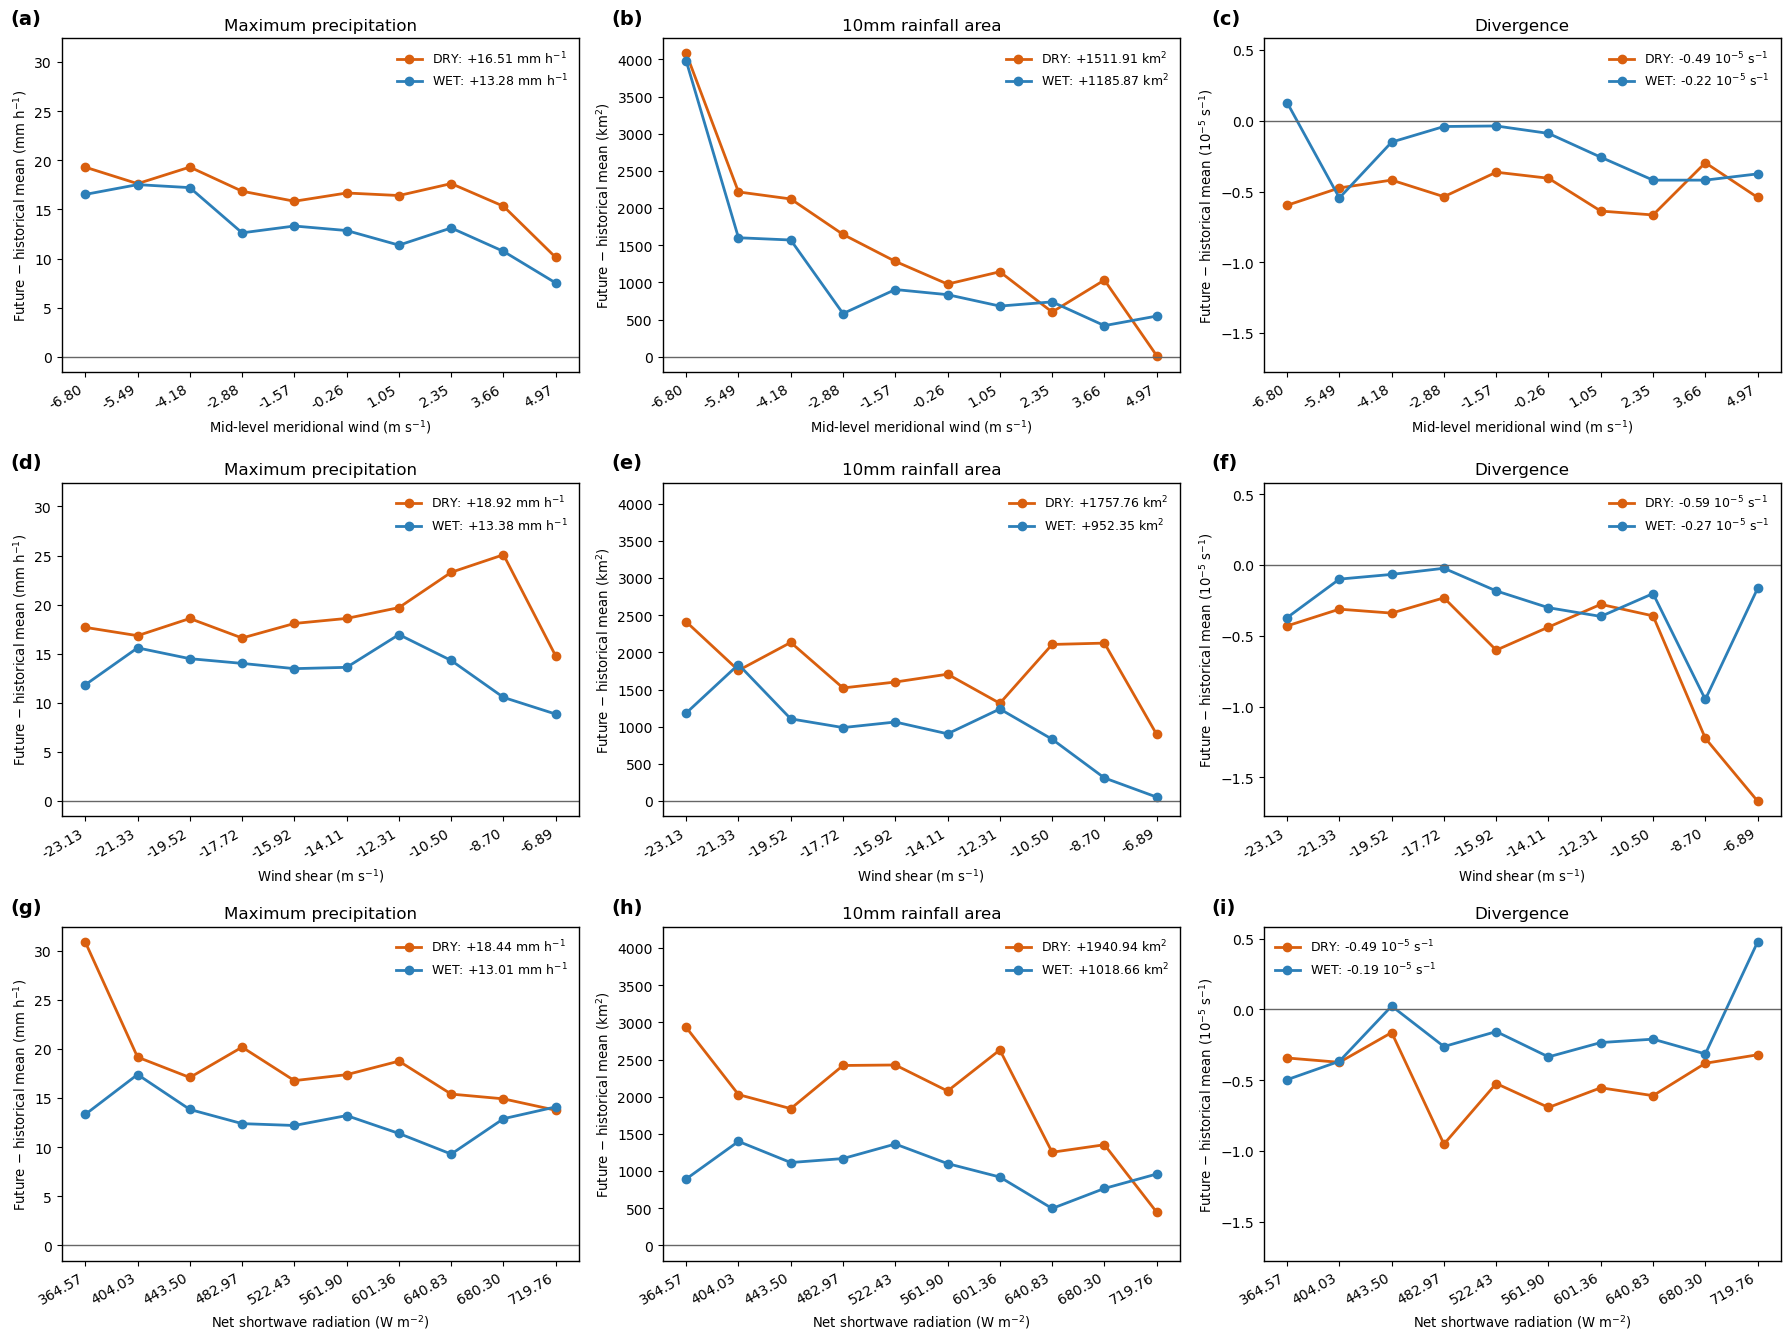

In [51]:
import numpy as np
import matplotlib.pyplot as plt

output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/v_mid_BINS_LINEAR_SFig5.jpg'

# Binning settings
bin_tag = '_2deg'              # '_2deg' or '_fullBox'
radiation_prefix = 'sw_net'
n_bins = 10                    # number of equally spaced bins

wet_col, dry_col = '#2C7FB8', '#D95F0E'
smvar = 'SM_2deg'
pvar, avar, dvar = 'pmax', 'area_10mm', 'div_1deg'

binning = [
    ('v_mid' + bin_tag, r'Mid-level meridional wind (m s$^{-1}$)', 'm/s'),
    ('shear' + bin_tag, r'Wind shear (m s$^{-1}$)', 'm/s'),
    (radiation_prefix + bin_tag, r'Net shortwave radiation (W m$^{-2}$)', 'W/m²')
]

panels = [
    (pvar, 1, r'mm h$^{-1}$', 'Maximum precipitation'),
    (avar, 4.4**2, r'km$^2$', '10mm rainfall area'),
    (dvar, 1e5, r'$10^{-5}$ s$^{-1}$', 'Divergence')
]

# DRY/WET selection
hist_dry = (lahist[smvar] < histp25) & hist_area
hist_wet = (lahist[smvar] > histp75) & hist_area
fut_dry = (lafut[smvar] < futp25) & fut_area
fut_wet = (lafut[smvar] > futp75) & fut_area

groups = [
    ('DRY', hist_dry, fut_dry, dry_col),
    ('WET', hist_wet, fut_wet, wet_col)
]


def binned_future_difference(var, hist_mask, fut_mask, binvar, edges):
    diffs, hmeans, fmeans, nhist, nfut = [], [], [], [], []

    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        last = i == len(edges) - 2

        hbin = hist_mask & (lhist[binvar] >= lo) & (
            (lhist[binvar] <= hi) if last else (lhist[binvar] < hi))

        fbin = fut_mask & (lfut[binvar] >= lo) & (
            (lfut[binvar] <= hi) if last else (lfut[binvar] < hi))

        hmean = lahist.loc[hbin, var].mean()
        fmean = lafut.loc[fbin, var].mean()

        hmeans.append(hmean)
        fmeans.append(fmean)
        diffs.append(fmean - hmean)
        nhist.append(hbin.sum())
        nfut.append(fbin.sum())

    return tuple(np.array(x) for x in [diffs, hmeans, fmeans, nhist, nfut])


def change_label(label, change, hist, factor, unit):
    valid = np.isfinite(change) & np.isfinite(hist)
    absolute = np.mean(change[valid]) if valid.any() else np.nan
    baseline = np.mean(hist[valid]) if valid.any() else np.nan
    relative = 100 * absolute / baseline if np.isfinite(baseline) and baseline != 0 else np.nan
    return f'{label}: {absolute * factor:+.2f} {unit}'   # ({relative:+.1f}%)


fig, axes = plt.subplots(3, 3, figsize=(18, 13.5), sharex='row', sharey='col')
results = {}

for row, (binvar, xlabel, binunit) in enumerate(binning):

    # 10 equally spaced bins between HIST min and max,
    # applied unchanged to both climates
    hvals = np.asarray(lhist[binvar], dtype=float)
    hvals = hvals[np.isfinite(hvals)]

    edges = np.linspace(np.nanpercentile(hvals,1), np.nanpercentile(hvals,99), n_bins + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    row_results = {}

    for col, (var, factor, unit, title) in enumerate(panels):
        ax = axes[row, col]

        for label, hmask, fmask, color in groups:
            values = binned_future_difference(var, hmask, fmask, binvar, edges)
            row_results[(var, label)] = values

            change, hist, future, nhist, nfut = values
            legend = change_label(label, change, hist, factor, unit)

            ax.plot(centres, change * factor, marker='o', lw=2,
                    color=color, label=legend)

        ax.axhline(0, color='0.4', lw=1)
        ax.set_ylabel(f'Future $-$ historical mean ({unit})')
        ax.set_title(title)

        ax.text(-0.10, 1.03, f'({chr(97 + row * 3 + col)})',
                transform=ax.transAxes, fontsize=14, fontweight='bold',
                color='black', va='bottom', ha='left')

        ax.set_xticks(centres)
        ax.set_xticklabels([f'{v:.2f}' for v in centres],
                           rotation=30, ha='right')

        ax.set_xlabel(xlabel)
        ax.legend(frameon=False, fontsize=9)

    results[binvar] = {
        'edges': edges,
        'centres': centres,
        'values': row_results
    }

    # Counts: selected storms per bin
    print(f'\nBinning by {binvar}')

    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        summaries = []

        for label, _, _, _ in groups:
            dp, _, _, nh, nf = row_results[(pvar, label)]
            da = row_results[(avar, label)][0]
            dd = row_results[(dvar, label)][0]

            summaries.append(
                f'{label}: H={nh[i]}, F={nf[i]}, '
                f'ΔPmax={dp[i]:.2f}, '
                f'ΔArea={da[i] * 4.4**2:.2f}, '
                f'ΔDiv={dd[i]:.2e}'
            )

        print(f'{lo:.2f} to {hi:.2f} {binunit} | ' +
              ' | '.join(summaries))

plt.tight_layout()
fig.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()


Binning by v_mid_2deg
-7.45 to -4.55 m/s | DRY: H=699, F=601, ΔPmax=18.00, ΔArea=2824.26, ΔDiv=-3.89e-06 | WET: H=297, F=350, ΔPmax=17.29, ΔArea=2251.16, ΔDiv=-2.96e-06
-4.55 to -3.50 m/s | DRY: H=663, F=434, ΔPmax=19.94, ΔArea=1929.38, ΔDiv=-5.50e-06 | WET: H=316, F=270, ΔPmax=17.09, ΔArea=1438.29, ΔDiv=-1.90e-06
-3.50 to -2.71 m/s | DRY: H=666, F=390, ΔPmax=16.32, ΔArea=1693.55, ΔDiv=-4.12e-06 | WET: H=326, F=257, ΔPmax=13.33, ΔArea=769.36, ΔDiv=-3.87e-06
-2.71 to -2.02 m/s | DRY: H=512, F=337, ΔPmax=18.26, ΔArea=1831.68, ΔDiv=-6.94e-06 | WET: H=463, F=254, ΔPmax=14.01, ΔArea=678.06, ΔDiv=1.70e-06
-2.02 to -1.36 m/s | DRY: H=517, F=314, ΔPmax=14.02, ΔArea=976.86, ΔDiv=-3.13e-06 | WET: H=417, F=289, ΔPmax=11.05, ΔArea=790.92, ΔDiv=-9.82e-07
-1.36 to -0.65 m/s | DRY: H=460, F=305, ΔPmax=15.84, ΔArea=1074.52, ΔDiv=-4.04e-06 | WET: H=482, F=350, ΔPmax=13.21, ΔArea=834.16, ΔDiv=1.12e-06
-0.65 to 0.12 m/s | DRY: H=382, F=267, ΔPmax=18.67, ΔArea=1253.05, ΔDiv=-3.70e-06 | WET: H=549, F=294,

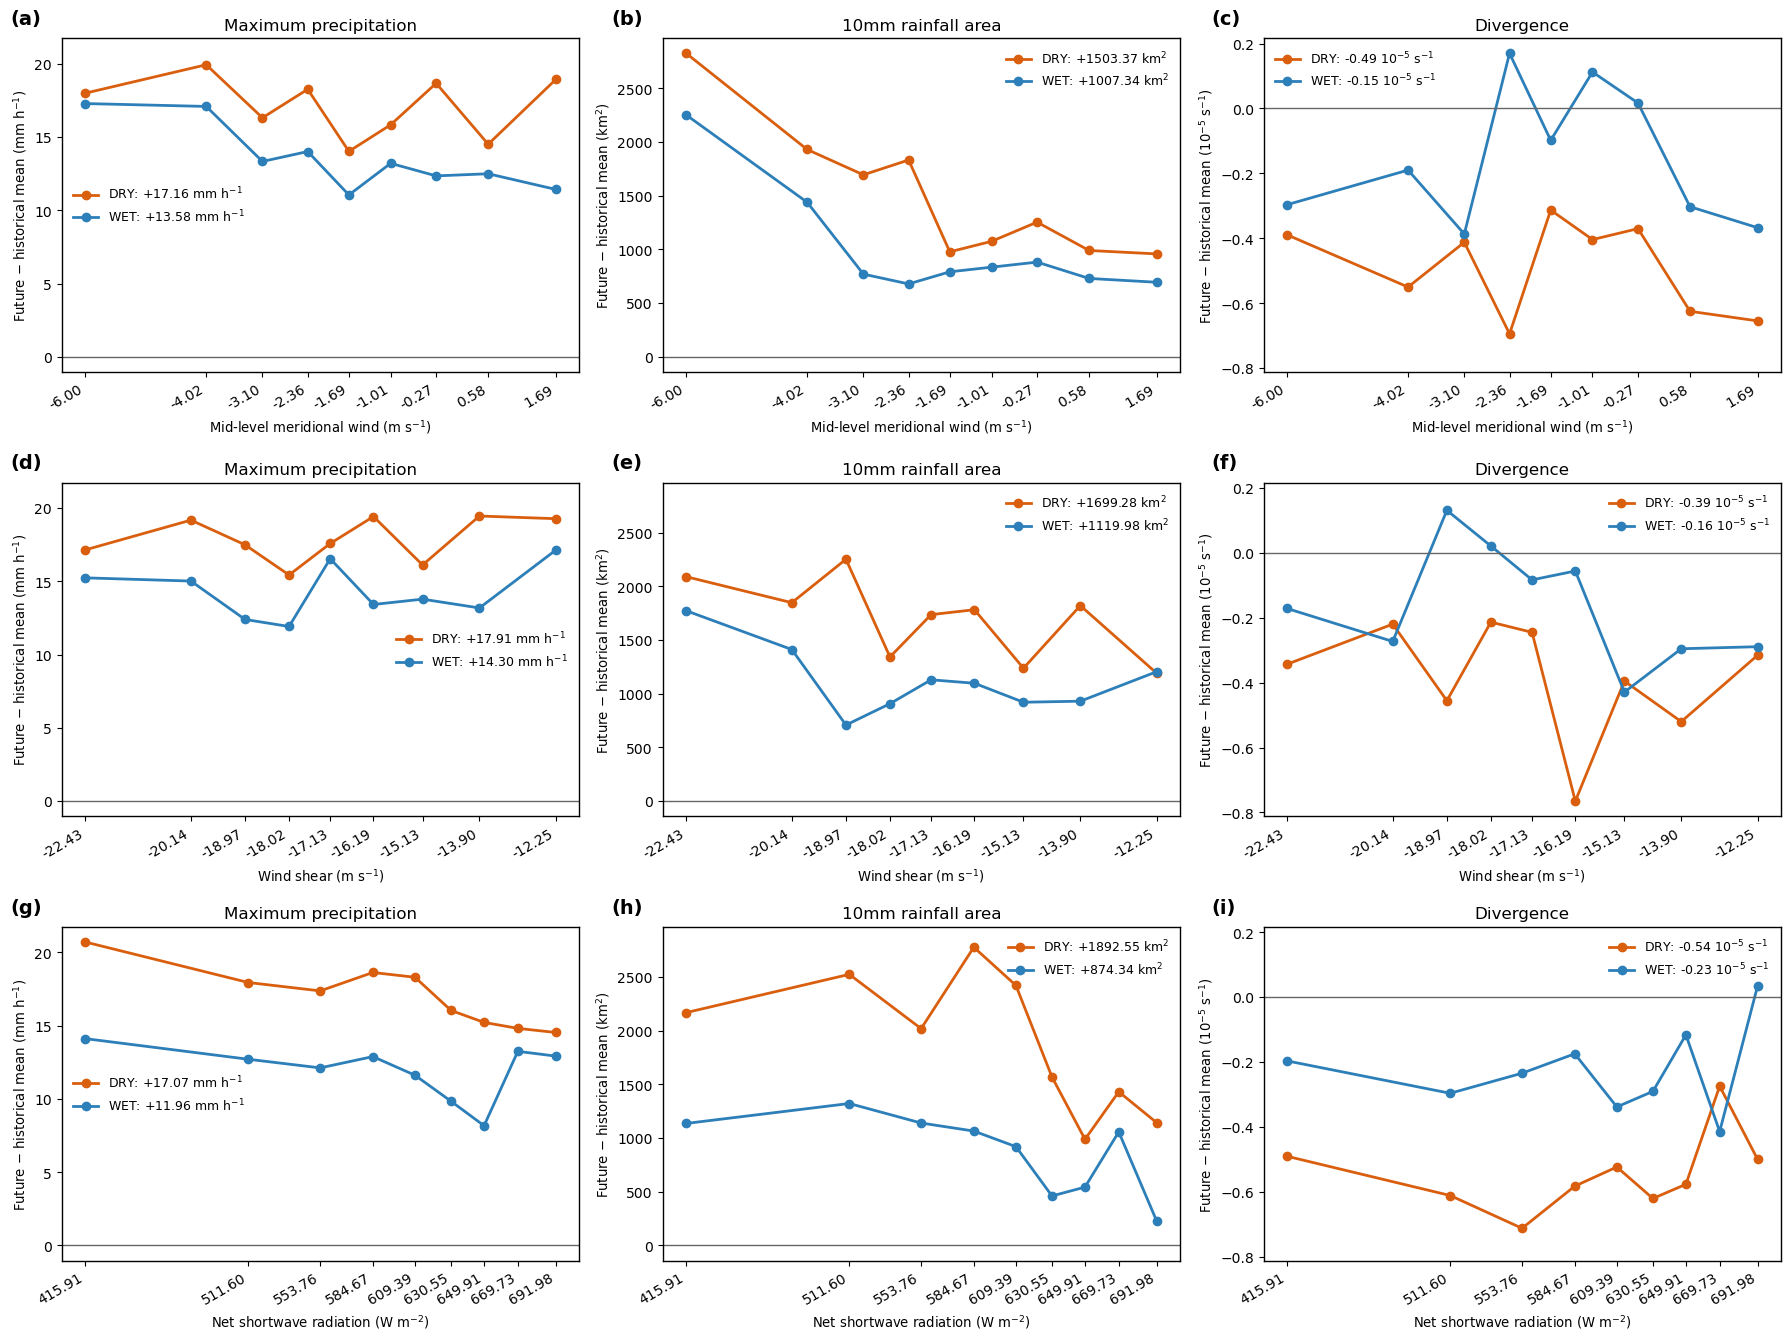

In [59]:
import numpy as np
import matplotlib.pyplot as plt

output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/v_mid_BINS_SFig5.jpg'

# Binning settings: change independently of SM selection and plotted variables
bin_tag = '_2deg'                       # '_2deg' or '_fullBox'
radiation_prefix = 'sw_net'
bin_percentiles = np.arange(1, 100, 10)   

wet_col, dry_col = '#2C7FB8', '#D95F0E'
smvar = 'SM_2deg'
pvar, avar, dvar = 'pmax', 'area_10mm', 'div_1deg'

binning = [
    ('v_mid' + bin_tag, r'Mid-level meridional wind (m s$^{-1}$)', 'm/s'),
    ('shear' + bin_tag, r'Wind shear (m s$^{-1}$)', 'm/s'),
    (radiation_prefix + bin_tag, r'Net shortwave radiation (W m$^{-2}$)', 'W/m²')
]

panels = [
    (pvar, 1, r'mm h$^{-1}$', 'Maximum precipitation'),
    (avar, 4.4**2, r'km$^2$', '10mm rainfall area'),
    (dvar, 1e5, r'$10^{-5}$ s$^{-1}$', 'Divergence')
]

# Existing DRY/WET selection
hist_dry = (lahist[smvar] < histp25) & hist_area
hist_wet = (lahist[smvar] > histp75) & hist_area
fut_dry = (lafut[smvar] < futp25) & fut_area
fut_wet = (lafut[smvar] > futp75) & fut_area

groups = [
    ('DRY', hist_dry, fut_dry, dry_col),
    ('WET', hist_wet, fut_wet, wet_col)
]

def binned_future_difference(var, hist_mask, fut_mask, binvar, edges):
    diffs, hmeans, fmeans, nhist, nfut = [], [], [], [], []

    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        last = i == len(edges) - 2
        hbin = hist_mask & (lhist[binvar] >= lo) & (
            (lhist[binvar] <= hi) if last else (lhist[binvar] < hi))
        fbin = fut_mask & (lfut[binvar] >= lo) & (
            (lfut[binvar] <= hi) if last else (lfut[binvar] < hi))

        hmean = lahist.loc[hbin, var].mean()
        fmean = lafut.loc[fbin, var].mean()
        hmeans.append(hmean)
        fmeans.append(fmean)
        diffs.append(fmean - hmean)
        nhist.append(hbin.sum())
        nfut.append(fbin.sum())

    return tuple(np.array(x) for x in [diffs, hmeans, fmeans, nhist, nfut])

def change_label(label, change, hist, factor, unit):
    valid = np.isfinite(change) & np.isfinite(hist)
    absolute = np.mean(change[valid]) if valid.any() else np.nan
    baseline = np.mean(hist[valid]) if valid.any() else np.nan
    relative = 100 * absolute / baseline if np.isfinite(baseline) and baseline != 0 else np.nan
    return f'{label}: {absolute * factor:+.2f} {unit}' # ({relative:+.1f}%)

fig, axes = plt.subplots(3, 3, figsize=(18, 13.5), sharex='row', sharey='col')
results = {}

for row, (binvar, xlabel, binunit) in enumerate(binning):
    # HIST percentile edges for this variable, applied unchanged to both climates
    edges = np.unique(np.nanpercentile(lhist[binvar], bin_percentiles))
    if len(edges) < 2:
        raise ValueError(f'{binvar}: fewer than two distinct bin edges.')
    centres = 0.5 * (edges[:-1] + edges[1:])
    row_results = {}

    for col, (var, factor, unit, title) in enumerate(panels):
        ax = axes[row, col]

        for label, hmask, fmask, color in groups:
            values = binned_future_difference(var, hmask, fmask, binvar, edges)
            row_results[(var, label)] = values
            change, hist, future, nhist, nfut = values

            legend = change_label(label, change, hist, factor, unit)
            ax.plot(centres, change * factor, marker='o', lw=2,
                    color=color, label=legend)

        ax.axhline(0, color='0.4', lw=1)
        ax.set_ylabel(f'Future $-$ historical mean ({unit})')
        ax.set_title(title)
        ax.text(-0.10, 1.03, f'({chr(97 + row * 3 + col)})',
                transform=ax.transAxes, fontsize=14, fontweight='bold',
                color='black', va='bottom', ha='left')
        ax.set_xticks(centres)
        ax.set_xticklabels([f'{v:.2f}' for v in centres], rotation=30, ha='right')
        ax.set_xlabel(xlabel)
        ax.legend(frameon=False, fontsize=9)

    results[binvar] = {'edges': edges, 'centres': centres, 'values': row_results}

    # Counts retain the original meaning: selected storms per bin
    print(f'\nBinning by {binvar}')
    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        summaries = []
        for label, _, _, _ in groups:
            dp, _, _, nh, nf = row_results[(pvar, label)]
            da = row_results[(avar, label)][0]
            dd = row_results[(dvar, label)][0]
            summaries.append(
                f'{label}: H={nh[i]}, F={nf[i]}, ΔPmax={dp[i]:.2f}, '
                f'ΔArea={da[i] * 4.4**2:.2f}, ΔDiv={dd[i]:.2e}')
        print(f'{lo:.2f} to {hi:.2f} {binunit} | ' + ' | '.join(summaries))

plt.tight_layout()
fig.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()

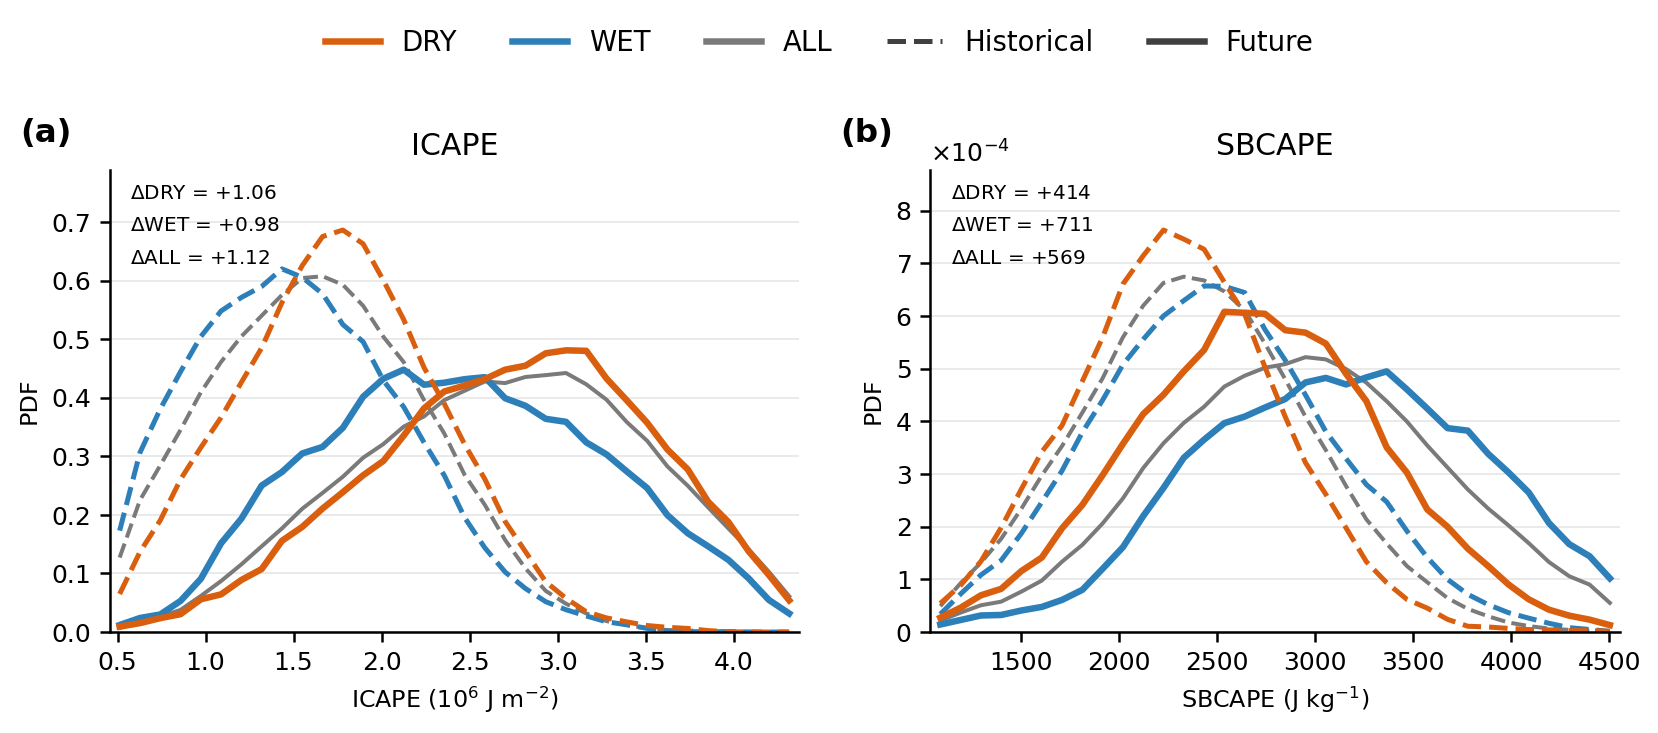

In [57]:
# Run after loading the matched mean (lhist/lfut) and anomaly (lahist/lafut) tables.
dtag = '1deg'                     # '0.25deg', '1deg', '2deg' or 'fullBox'
output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/SFig_CAPE_PDFs_' + dtag + '.jpg'
dry_col, wet_col, all_col = '#D95F0E', '#2C7FB8', '0.48'
nbins, smooth, qrange = 34, 3, (1, 99)

# Variable, title, x label, scale; both panels use ABSOLUTE values.
panels = [('ICAPEfull_' + dtag, 'ICAPE', r'ICAPE ($10^{6}$ J m$^{-2}$)', 1e-6),
          ('SBCAPEfull_' + dtag, 'SBCAPE', r'SBCAPE (J kg$^{-1}$)', 1)]

# Same filters and climate-specific SM-anomaly quartiles as Fig. 2.
# Mean/anomaly tables must already contain the same cases in the same order.
for mean, anom in [(lhist, lahist), (lfut, lafut)]:
    if not mean.index.equals(anom.index):
        raise ValueError('Match mean and anomaly tables before applying the SM masks.')

hist_sample = (lhist['v_mid_fullBox'].between(-50, 50, inclusive='neither') &
               (lhist['area'] * 4.4**2 < 500000))
fut_sample = (lfut['v_mid_fullBox'].between(-50, 50, inclusive='neither') &
              (lfut['area'] * 4.4**2 < 500000))
histp25, histp75 = np.nanpercentile(lahist.loc[hist_sample, 'SM_2deg'], [25, 75])
futp25, futp75 = np.nanpercentile(lafut.loc[fut_sample, 'SM_2deg'], [25, 75])

hist_masks = {'ALL': hist_sample, 'DRY': hist_sample & (lahist['SM_2deg'] < histp25),
              'WET': hist_sample & (lahist['SM_2deg'] > histp75)}
fut_masks = {'ALL': fut_sample, 'DRY': fut_sample & (lafut['SM_2deg'] < futp25),
             'WET': fut_sample & (lafut['SM_2deg'] > futp75)}
colours = {'ALL': all_col, 'DRY': dry_col, 'WET': wet_col}

def clean(values, scale):
    values = np.asarray(values, dtype=float) * scale
    return values[np.isfinite(values)]

def pdf(values, bins):
    counts, edges = np.histogram(values, bins=bins)
    # Normalise by the full sample: cropping tails does not rescale each PDF.
    density = counts / (values.size * np.diff(edges))
    if smooth > 1:
        density = np.convolve(density, np.ones(smooth) / smooth, mode='same')
    return (edges[:-1] + edges[1:]) / 2, density

with plt.rc_context({'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 9.5,
                     'axes.linewidth': 1, 'svg.fonttype': 'none'}):
    fig, axs = plt.subplots(1, 2, figsize=(9.2, 4.0), dpi=180)

    for ax, letter, (var, title, xlabel, scale) in zip(axs, 'ab', panels):
        data = {}
        for climate, table, masks in [('HIST', lhist, hist_masks), ('FUT', lfut, fut_masks)]:
            for group, mask in masks.items():
                values = clean(table.loc[mask, var], scale)
                if values.size == 0:
                    raise ValueError(f'No finite values for {climate} {group}: {var}')
                data[climate, group] = values

        # Common bins for all six curves; range is based on the two ALL samples.
        pooled = np.concatenate([data['HIST', 'ALL'], data['FUT', 'ALL']])
        lo, hi = np.percentile(pooled, qrange)
        if hi <= lo:
            raise ValueError(f'Insufficient variation for a PDF: {var}')
        bins = np.linspace(lo, hi, nbins + 1)
        ymax = 0
        for group in ['ALL', 'WET', 'DRY']:
            for climate, ls, lw in [('HIST', '--', 2), ('FUT', '-', 2.6)]:
                x, y = pdf(data[climate, group], bins)
                ax.plot(x, y, color=colours[group], ls=ls, lw=lw if group != 'ALL' else 1.6)
                ymax = max(ymax, y.max())

            
          
        decimals = 2 if var.startswith('ICAPE') else 0
        for i, group in enumerate(['DRY', 'WET', 'ALL']):
            delta = np.median(data['FUT', group]) - np.median(data['HIST', group])
            ax.text(0.03, 0.97 - i * 0.07,
                    fr'$\Delta${group} = {delta:+.{decimals}f}',
                    transform=ax.transAxes, ha='left', va='top',
                    fontsize=8, color='k')  #colours[group]


        ax.set(title=title, xlabel=xlabel, ylabel='PDF', xlim=(lo, hi), ylim=(0, ymax * 1.15))
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(direction='out', labelsize=10, width=1, length=4)
        ax.grid(axis='y', color='0.91', lw=0.7)
        ax.set_axisbelow(True)
        ax.text(-0.13, 1.045, f'({letter})', transform=ax.transAxes, ha='left',
                va='bottom', fontsize=13, fontweight='semibold', clip_on=False)

    handles = [Line2D([], [], color=colours[g], lw=2.6, label=g) for g in ['DRY', 'WET', 'ALL']]
    handles += [Line2D([], [], color='0.25', ls=ls, lw=lw, label=label)
                for ls, lw, label in [('--', 2, 'Historical'), ('-', 2.6, 'Future')]]
    fig.legend(handles=handles, frameon=False, ncol=5, loc='upper center',
               bbox_to_anchor=(0.5, 1.025), fontsize=11)

    axs[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    fig.tight_layout(rect=(0, 0, 1, 0.91), w_pad=2.2)
    
    fig.savefig(output_file, dpi=300, bbox_inches='tight')

    plt.show()


In [34]:
import numpy as np
import pandas as pd

# Fixed historical SM thresholds
p25, p75 = np.nanpercentile(lahist['SM_1deg'], [25, 75])

def soil_groups(df):
    sm = df['SM_1deg']
    return {'DRY': sm < p25, 'MID': (sm >= p25) & (sm <= p75), 'WET': sm > p75}

def decompose_mean_change(var, factor=1):
    hg, fg = soil_groups(lahist), soil_groups(lafut)
    rows = []

    for g in ['DRY', 'MID', 'WET']:
        ph, pf = hg[g].mean(), fg[g].mean()
        mh = np.nanmean(lahist.loc[hg[g], var] * factor)
        mf = np.nanmean(lafut.loc[fg[g], var] * factor)

        freq = (pf-ph) * (mf+mh)/2
        intensity = (mf-mh) * (pf+ph)/2
        contribution = freq + intensity

        rows.append([g, ph, pf, mh, mf, freq, intensity, contribution])

    out = pd.DataFrame(rows, columns=[
        'group', 'fraction_hist', 'fraction_fut',
        'mean_hist', 'mean_fut',
        'frequency_effect', 'within_state_effect', 'total_contribution'
    ])

    total_change = np.nanmean(lafut[var]*factor) - np.nanmean(lahist[var]*factor)
    out['fraction_of_total_change_%'] = 100*out['total_contribution']/total_change

    print(f'\nTotal mean change: {total_change:.3f}')
    print(f'Sum of contributions: {out.total_contribution.sum():.3f}')
    return out

In [35]:
pmax_decomp = decompose_mean_change('pmax')
area_decomp = decompose_mean_change('area_10mm', factor=4.4**2)

print(pmax_decomp)
print(area_decomp)


Total mean change: 14.719
Sum of contributions: 14.689

Total mean change: 1301.133
Sum of contributions: 1299.829
  group  fraction_hist  fraction_fut  mean_hist   mean_fut  frequency_effect  \
0   DRY       0.249724      0.392529  25.269237  41.062392          4.736244   
1   MID       0.499447      0.438533  23.421998  36.491867         -1.824787   
2   WET       0.249724      0.167762  22.531595  36.973608         -2.438568   

   within_state_effect  total_contribution  fraction_of_total_change_%  
0             5.071593            9.807837                   66.633716  
1             6.129641            4.304854                   29.246854  
2             3.014666            0.576098                    3.913965  
  group  fraction_hist  fraction_fut    mean_hist     mean_fut  \
0   DRY       0.249724      0.392529  1694.826151  3065.861065   
1   MID       0.499447      0.438533  1411.253591  2570.036182   
2   WET       0.249724      0.167762  1150.805475  2293.796751   

   fre

HIST unique storm locations: 15,126
FUT unique storm locations:  10,721
Intersection locations:      937


,test,hist_locations,fut_locations,hist_bg,fut_bg,hist_storm,fut_storm,bg_ratio,storm_ratio,hist_enrichment,...,enrichment_ratio,enrichment_change_%,fut_storm_background_only,extra_association_pp,background_share_%,association_share_%,hist_bg_n,fut_bg_n,hist_storm_n,fut_storm_n
0,Own locations,15126,10721,0.1921,0.2493,0.2462,0.3976,1.2975,1.6150,1.2815,...,1.2446,24.4643,0.3194,7.8149,48.3829,51.6171,12083470,8509689,15939,11039
1,Intersection,937,937,0.1914,0.2801,0.2446,0.4246,1.4637,1.7359,1.2781,...,1.1859,18.5943,0.3580,6.6566,63.0151,36.9849,747067,739142,1014,961



OWN LOCATIONS
Locations:                  HIST 15,126 | FUT 10,721
Background DRY occurrence:  19.21% -> 24.93%
MCS-day DRY occurrence:     24.62% -> 39.76%

Background FUT/HIST ratio:  x1.298 (+29.8%)
MCS-day FUT/HIST ratio:     x1.615 (+61.5%)

HIST MCS/background enrich: 1.282
FUT  MCS/background enrich: 1.595
Enrichment FUT/HIST:        x1.245 (+24.5%)

FUT MCS DRY if background-only: 31.94%
Observed FUT MCS DRY:            39.76%
Extra association:               +7.81 percentage points

Share of MCS-day shift:
  background availability:       48.4%
  additional MCS association:    51.6%

INTERSECTION
Locations:                  HIST 937 | FUT 937
Background DRY occurrence:  19.14% -> 28.01%
MCS-day DRY occurrence:     24.46% -> 42.46%

Background FUT/HIST ratio:  x1.464 (+46.4%)
MCS-day FUT/HIST ratio:     x1.736 (+73.6%)

HIST MCS/background enrich: 1.278
FUT  MCS/background enrich: 1.516
Enrichment FUT/HIST:        x1.186 (+18.6%)

FUT MCS DRY if background-only: 35.80%
Observe

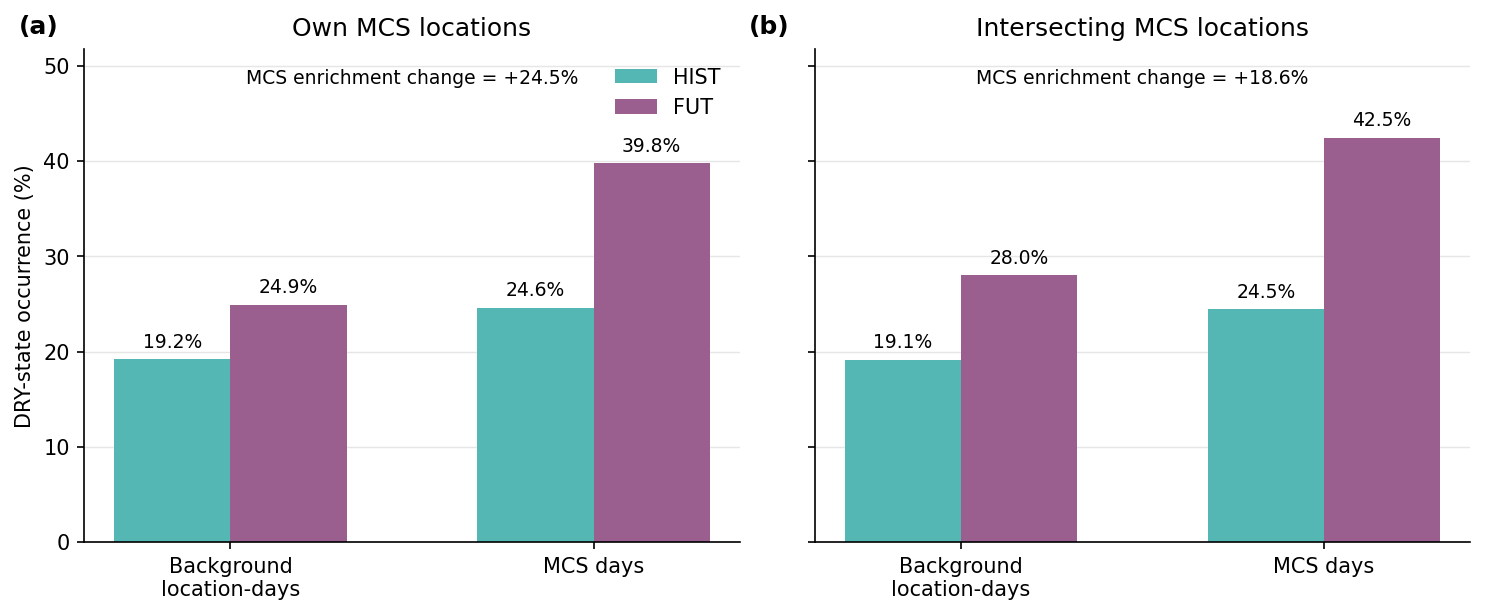


Saved: /home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/SFig_SM_background_own_vs_intersection.svg


In [2]:
# =============================================================================
# DRY-SM BACKGROUND vs MCS OCCURRENCE
# Test 1: each climate's OWN storm locations
# Test 2: INTERSECTION of HIST/FUT storm locations
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from shared.paths import load_paths
paths = load_paths()

# -----------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------
DRY_THRESHOLD = -3.069373148619687
YEARS = range(1998, 2007)

ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/SM_background_frequency"
CACHE = ROOT / "yearly_daily_cache"
LOCS = pd.read_csv(ROOT / "unique_storm_locations.csv")
HSTORM = pd.read_csv(ROOT / "storm_SM_audit_hist.csv")
FSTORM = pd.read_csv(ROOT / "storm_SM_audit_fut.csv")

OUTFIG = "/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/SFig_SM_background_own_vs_intersection.svg"

HIST_COL, FUT_COL = "#55B7B3", "#9a5f8f"


# =============================================================================
# Helpers
# =============================================================================

def cache_file(climate, year):
    return CACHE / f"background_SM_daily_{climate}_{year}.nc"


def fraction(values):
    v = np.asarray(values, dtype=float)
    good = np.isfinite(v)
    return np.sum(v[good] < DRY_THRESHOLD) / good.sum(), int(np.sum(v[good] < DRY_THRESHOLD)), int(good.sum())


def background_fraction(climate, location_ids):
    """Pool all valid unique location-days over the requested location IDs."""
    dry, valid = 0, 0
    location_ids = set(np.asarray(location_ids, dtype=int))

    for year in YEARS:
        with xr.open_dataset(cache_file(climate, year)) as ds:
            ids = ds["location"].values.astype(int)
            mask = np.isin(ids, list(location_ids))
            arr = ds["SM_2deg_anom"].values[:, mask]

        good = np.isfinite(arr)
        dry += int(np.sum(good & (arr < DRY_THRESHOLD)))
        valid += int(good.sum())

    return dry / valid, dry, valid


def storm_fraction(df, location_ids=None):
    """MCS fraction using the resampled values from the same daily cache."""
    use = df if location_ids is None else df[df["location_id"].isin(location_ids)]
    f, dry, valid = fraction(use["SM_2deg_resampled"])
    return f, dry, valid, len(use)


def calculate_test(name, hist_ids, fut_ids):
    """Calculate background, storm occurrence, enrichment and counterfactual."""
    bh, bh_dry, bh_n = background_fraction("hist", hist_ids)
    bf, bf_dry, bf_n = background_fraction("fut", fut_ids)

    sh, sh_dry, sh_n, sh_rows = storm_fraction(HSTORM, hist_ids)
    sf, sf_dry, sf_n, sf_rows = storm_fraction(FSTORM, fut_ids)

    bg_ratio = bf / bh
    storm_ratio = sf / sh
    enrich_h = sh / bh
    enrich_f = sf / bf
    enrich_ratio = enrich_f / enrich_h

    sf_bg_only = sh * bg_ratio
    extra_pp = 100 * (sf - sf_bg_only)

    total_shift = sf - sh
    bg_component = sf_bg_only - sh
    assoc_component = sf - sf_bg_only
    bg_share = 100 * bg_component / total_shift if not np.isclose(total_shift, 0) else np.nan
    assoc_share = 100 * assoc_component / total_shift if not np.isclose(total_shift, 0) else np.nan

    return {
        "test": name,
        "hist_locations": len(hist_ids), "fut_locations": len(fut_ids),
        "hist_bg": bh, "fut_bg": bf,
        "hist_storm": sh, "fut_storm": sf,
        "bg_ratio": bg_ratio, "storm_ratio": storm_ratio,
        "hist_enrichment": enrich_h, "fut_enrichment": enrich_f,
        "enrichment_ratio": enrich_ratio,
        "enrichment_change_%": 100 * (enrich_ratio - 1),
        "fut_storm_background_only": sf_bg_only,
        "extra_association_pp": extra_pp,
        "background_share_%": bg_share, "association_share_%": assoc_share,
        "hist_bg_n": bh_n, "fut_bg_n": bf_n,
        "hist_storm_n": sh_n, "fut_storm_n": sf_n
    }


# =============================================================================
# Location sets
# =============================================================================

hist_ids = LOCS.loc[LOCS["hist_location"].astype(bool), "location_id"].astype(int).to_numpy()
fut_ids = LOCS.loc[LOCS["fut_location"].astype(bool), "location_id"].astype(int).to_numpy()

intersection_ids = LOCS.loc[
    LOCS["hist_location"].astype(bool) & LOCS["fut_location"].astype(bool),
    "location_id"
].astype(int).to_numpy()

print(f"HIST unique storm locations: {len(hist_ids):,}")
print(f"FUT unique storm locations:  {len(fut_ids):,}")
print(f"Intersection locations:      {len(intersection_ids):,}")


# =============================================================================
# Run the two tests
# =============================================================================

own = calculate_test("Own locations", hist_ids, fut_ids)
inter = calculate_test("Intersection", intersection_ids, intersection_ids)

results = pd.DataFrame([own, inter])
display(results.round(4))


# =============================================================================
# Text-ready output
# =============================================================================

for r in [own, inter]:
    print("\n" + "=" * 72)
    print(r["test"].upper())
    print("=" * 72)

    print(f"Locations:                  HIST {r['hist_locations']:,} | FUT {r['fut_locations']:,}")
    print(f"Background DRY occurrence:  {100*r['hist_bg']:.2f}% -> {100*r['fut_bg']:.2f}%")
    print(f"MCS-day DRY occurrence:     {100*r['hist_storm']:.2f}% -> {100*r['fut_storm']:.2f}%")

    print(f"\nBackground FUT/HIST ratio:  x{r['bg_ratio']:.3f} ({100*(r['bg_ratio']-1):+.1f}%)")
    print(f"MCS-day FUT/HIST ratio:     x{r['storm_ratio']:.3f} ({100*(r['storm_ratio']-1):+.1f}%)")

    print(f"\nHIST MCS/background enrich: {r['hist_enrichment']:.3f}")
    print(f"FUT  MCS/background enrich: {r['fut_enrichment']:.3f}")
    print(f"Enrichment FUT/HIST:        x{r['enrichment_ratio']:.3f} ({r['enrichment_change_%']:+.1f}%)")

    print(f"\nFUT MCS DRY if background-only: {100*r['fut_storm_background_only']:.2f}%")
    print(f"Observed FUT MCS DRY:            {100*r['fut_storm']:.2f}%")
    print(f"Extra association:               {r['extra_association_pp']:+.2f} percentage points")

    print(f"\nShare of MCS-day shift:")
    print(f"  background availability:       {r['background_share_%']:.1f}%")
    print(f"  additional MCS association:    {r['association_share_%']:.1f}%")


# =============================================================================
# Plot: own locations versus intersection
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=150, sharey=True)

for ax, r, title in zip(axes, [own, inter], ["Own MCS locations", "Intersecting MCS locations"]):
    x = np.arange(2)
    width = 0.32

    hist = np.array([r["hist_bg"], r["hist_storm"]]) * 100
    fut = np.array([r["fut_bg"], r["fut_storm"]]) * 100

    ax.bar(x - width/2, hist, width, color=HIST_COL, label="HIST", zorder=2)
    ax.bar(x + width/2, fut, width, color=FUT_COL, label="FUT", zorder=2)

    for xx, yy in zip(x - width/2, hist):
        ax.text(xx, yy + 0.8, f"{yy:.1f}%", ha="center", va="bottom", fontsize=9)

    for xx, yy in zip(x + width/2, fut):
        ax.text(xx, yy + 0.8, f"{yy:.1f}%", ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(["Background\nlocation-days", "MCS days"])
    ax.set_title(title)
    ax.grid(axis="y", color="0.9", lw=0.7, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")

    ax.text(
        0.5, 0.96,
        f"MCS enrichment change = {r['enrichment_change_%']:+.1f}%",
        transform=ax.transAxes, ha="center", va="top", fontsize=9
    )

axes[0].set_ylabel("DRY-state occurrence (%)")
axes[0].legend(frameon=False)

ymax = max(
    own["hist_bg"], own["fut_bg"], own["hist_storm"], own["fut_storm"],
    inter["hist_bg"], inter["fut_bg"], inter["hist_storm"], inter["fut_storm"]
) * 100
axes[0].set_ylim(0, ymax * 1.22)

axes[0].text(-0.10, 1.03, "(a)", transform=axes[0].transAxes, fontsize=12, fontweight="semibold")
axes[1].text(-0.10, 1.03, "(b)", transform=axes[1].transAxes, fontsize=12, fontweight="semibold")

fig.tight_layout()
fig.savefig(OUTFIG, bbox_inches="tight")
plt.show()

print(f"\nSaved: {OUTFIG}")

In [4]:
(42.5-24.5)

18.0

In [5]:
(28-19.1)

8.899999999999999

In [ ]:
((42.5-24.5)-(28-19.1))

In [6]:
histrat = 24.5/19.1
futrat = 42.5/28.0

In [7]:
histrat

1.2827225130890052

In [8]:
futrat

1.5178571428571428

In [9]:
futrat/histrat

1.1833090379008746

In [10]:
futrat-histrat

0.2351346297681376